<a href="https://colab.research.google.com/github/starsyntaxx/MarketIQ/blob/main/notebooks/02_exploratory_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import zipfile
import os

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")

In [3]:
def extract_file_from_drive(zip_path, file_name, extract_to='/content/extracted'):

    os.makedirs(extract_to, exist_ok=True)

    with zipfile.ZipFile(zip_path, 'r') as zip_ref:

        if file_name not in zip_ref.namelist():
            raise FileNotFoundError(
                f"{file_name} not found in the ZIP archive."
            )

        zip_ref.extract(file_name, extract_to)

    extracted_path = os.path.join(extract_to, file_name)

    return extracted_path

In [4]:
pd.reset_option('display.max_columns')
pd.reset_option('display.max_rows')

In [5]:
zip_path = "/content/drive/MyDrive/ML PROJECTS/MarketIQ/data/raw/NGA_2025_HFCP_v01_M_CSV.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    print(zip_ref.namelist())

['Raw_data_spatialrev.csv', 'level2_price_yellow_maize.csv', 'level2_price_yam.csv', 'level2_price_white_maize.csv', 'level2_price_white_beans.csv', 'level2_price_soybean.csv', 'level2_price_sorghum.csv', 'level2_price_local_rice.csv', 'level2_price_imported_rice.csv', 'level2_price_garri.csv', 'level2_price_brown_beans.csv']


In [6]:
csv_files = [
    'Raw_data_spatialrev.csv',
    'level2_price_yellow_maize.csv',
    'level2_price_yam.csv',
    'level2_price_white_maize.csv',
    'level2_price_white_beans.csv',
    'level2_price_soybean.csv',
    'level2_price_sorghum.csv',
    'level2_price_local_rice.csv',
    'level2_price_imported_rice.csv',
    'level2_price_garri.csv',
    'level2_price_brown_beans.csv'
]

dataframes = {}

for i, file_name in enumerate(csv_files, start=1):
    try:
        extracted_path = extract_file_from_drive(zip_path, file_name)
        df_name = f'df_{i}'
        globals()[df_name] = pd.read_csv(extracted_path)
        dataframes[df_name] = file_name
        print(f"Successfully loaded '{file_name}' into variable `{df_name}` (Shape: {globals()[df_name].shape})")
    except Exception as e:
        print(f"Failed to load {file_name}: {e}")

Successfully loaded 'Raw_data_spatialrev.csv' into variable `df_1` (Shape: (220214, 72))
Successfully loaded 'level2_price_yellow_maize.csv' into variable `df_2` (Shape: (190873, 25))
Successfully loaded 'level2_price_yam.csv' into variable `df_3` (Shape: (173180, 25))
Successfully loaded 'level2_price_white_maize.csv' into variable `df_4` (Shape: (199828, 25))
Successfully loaded 'level2_price_white_beans.csv' into variable `df_5` (Shape: (202059, 25))
Successfully loaded 'level2_price_soybean.csv' into variable `df_6` (Shape: (186293, 25))
Successfully loaded 'level2_price_sorghum.csv' into variable `df_7` (Shape: (185067, 25))
Successfully loaded 'level2_price_local_rice.csv' into variable `df_8` (Shape: (198630, 25))
Successfully loaded 'level2_price_imported_rice.csv' into variable `df_9` (Shape: (141612, 25))
Successfully loaded 'level2_price_garri.csv' into variable `df_10` (Shape: (202731, 25))
Successfully loaded 'level2_price_brown_beans.csv' into variable `df_11` (Shape: (17

In [7]:
print("Available DataFrame variables:")
for key, val in dataframes.items():
    print(f"{key}: {val}")

Available DataFrame variables:
df_1: Raw_data_spatialrev.csv
df_2: level2_price_yellow_maize.csv
df_3: level2_price_yam.csv
df_4: level2_price_white_maize.csv
df_5: level2_price_white_beans.csv
df_6: level2_price_soybean.csv
df_7: level2_price_sorghum.csv
df_8: level2_price_local_rice.csv
df_9: level2_price_imported_rice.csv
df_10: level2_price_garri.csv
df_11: level2_price_brown_beans.csv


### Baseline Analysis of `df_1` (Raw_data_spatialrev.csv)

In [8]:
# 1. General Overview of the dataset
print("=== Dataset Shape ===")
print(df_1.shape)

print("\n=== Info ===")
display(df_1.info(max_cols=100))

=== Dataset Shape ===
(220214, 72)

=== Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220214 entries, 0 to 220213
Data columns (total 72 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   fid           220214 non-null  int64  
 1   submissio     220214 non-null  int64  
 2   date          220214 non-null  object 
 3   zonecode1     220214 non-null  int64  
 4   geopol_zon    220214 non-null  object 
 5   statecode1    220214 non-null  int64  
 6   zonelabel1    220214 non-null  object 
 7   statelabel    220214 non-null  object 
 8   lga           220214 non-null  int64  
 9   lgalabel      220214 non-null  object 
 10  sector        220214 non-null  object 
 11  vc_id         220214 non-null  object 
 12  staff_vali    220214 non-null  int64  
 13  consent       220214 non-null  int64  
 14  market_typ    220214 non-null  object 
 15  price_cate    220214 non-null  object 
 16  market_tim    220214 non-null  int64  
 17 

None

In [9]:
# 2. Display the first few rows to examine data structure
display(df_1.head().T)

,0,1,2,3,4
fid,0,1,2,3,4
submissio,4316,5346,5541,5680,5690
date,12/1/2024,12/1/2024,12/2/2024,12/2/2024,12/2/2024
zonecode1,1,1,3,1,1
geopol_zon,nbsnorthcentral,nbsnorthcentral,nbsnorthwest,nbsnorthcentral,nbsnorthcentral
...,...,...,...,...,...
gps_coords,9.0266823 7.607355399999999 0.0 0.0,9.0266823 7.607355399999999 0.0 0.0,10.4607247 7.4472635 630.2872318788975 0.0,7.1928081 8.146351333333333 218.474 0.0,7.192811033333333 8.14631625 222.09 0.0
gps_latitu,9.026682,9.026682,10.460725,7.192808,7.192811
gps_longit,7.607355,7.607355,7.447264,8.146351,8.146316
gps_precis,NaN,NaN,NaN,NaN,NaN


In [10]:
# 3. Missing Value Analysis
missing_values = df_1.isnull().sum()
missing_percentage = (df_1.isnull().sum() / len(df_1)) * 100
missing_df = pd.DataFrame({'Missing Values': missing_values, 'Percentage (%)': missing_percentage})
missing_df = missing_df[missing_df['Missing Values'] > 0].sort_values(by='Missing Values', ascending=False)

print("=== Columns with Missing Values ===")
if not missing_df.empty:
    display(missing_df)
else:
    print("No missing values found!")

=== Columns with Missing Values ===


,Missing Values,Percentage (%)
uom_import,63945,29.037663
q_rice,63945,29.037663
price_impo,63945,29.037663
price_impo_1,63945,29.037663
q_yam,36714,16.671965
uom_yam,36714,16.671965
price_yam_,36714,16.671965
price_yam,36714,16.671965
q_brownbea,28999,13.168554
price_br_1,28999,13.168554


In [11]:
# 4. Summary Statistics for numerical and categorical variables
print("=== Summary Statistics (Numerical) ===")
display(df_1.describe())

print("\n=== Summary Statistics (Categorical) ===")
display(df_1.describe(include=['object', 'category']))

=== Summary Statistics (Numerical) ===


,fid,submissio,zonecode1,statecode1,lga,staff_vali,consent,market_tim,uom_ymaize,q_ymaize,...,price_yam,price_yam_,uom_soyabe,q_soyabean,price_soya,price_so_2,gps_latitu,gps_longit,gps_precis,count
count,220214.000000,220214.000000,220214.000000,220214.000000,220214.000000,220214.000000,220214.000000,2.202140e+05,203418.000000,203418.00000,...,1.835000e+05,1.835000e+05,199310.000000,199310.000000,1.993100e+05,1.993100e+05,220214.000000,220214.000000,219218.000000,220214.0
mean,110106.500000,113258.710177,3.471292,19.347312,1946.054025,0.109984,0.999755,5.980224e+03,6.091645,1.05239,...,3.395627e+03,1.885100e+03,5.628720,1.048367,1.269427e+04,5.744930e+03,8.529373,7.287308,93.935890,1.0
std,63570.450427,63699.305641,1.758067,10.325774,1031.751518,0.312870,0.015657,1.842417e+06,20.959550,0.42878,...,1.899352e+05,1.899225e+05,19.809292,0.395232,1.881595e+06,1.334927e+06,2.514299,2.430840,453.606456,0.0
min,0.000000,189.000000,1.000000,1.000000,101.000000,0.000000,0.000000,-8.500000e+01,0.160000,1.00000,...,1.000000e+02,7.142857e+00,0.200000,1.000000,1.000000e+02,1.050000e+00,4.426009,2.714769,1.000000,1.0
25%,55053.250000,58209.250000,2.000000,10.000000,1019.000000,0.000000,1.000000,1.000000e+01,0.670000,1.00000,...,1.700000e+03,8.571429e+02,0.650000,1.000000,1.100000e+03,1.125000e+03,6.456500,5.264294,4.000000,1.0
50%,110106.500000,113306.500000,3.000000,19.000000,1944.000000,0.000000,1.000000,2.000000e+01,1.300000,1.00000,...,2.400000e+03,1.142857e+03,1.400000,1.000000,1.800000e+03,1.428571e+03,7.843022,7.336395,5.000000,1.0
75%,165159.750000,168395.750000,5.000000,28.000000,2806.000000,0.000000,1.000000,4.000000e+01,1.300000,1.00000,...,3.200000e+03,1.714286e+03,1.400000,1.000000,2.500000e+03,1.857143e+03,10.488568,8.529103,5.000000,1.0
max,220213.000000,223519.000000,6.000000,37.000000,3706.000000,1.000000,1.000000,6.584807e+08,100.000000,9.00000,...,8.135568e+07,8.135568e+07,100.000000,9.000000,8.033116e+08,5.737940e+08,13.754103,14.209325,6114.000000,1.0



=== Summary Statistics (Categorical) ===


,date,geopol_zon,zonelabel1,statelabel,lgalabel,sector,vc_id,market_typ,price_cate,maize_yell,maize_whit,sorghum,imported_r,local_rice,brown_bean,white_bean,garri_conf,yam_confir,soyabeans,gps_coords
count,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214
unique,217,6,6,37,591,2,901,10,4,3,3,3,3,3,3,3,3,3,3,214904
top,11/29/2024,nbsnorthwest,North West,KANO,AKURE SOUTH,Urban,BORNO2,RoadSide_shops_street vendors,Retail,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,4.6880963 6.3161275 0.0 1700.0
freq,1452,45613,45923,9907,3945,151148,1039,67792,193398,203418,212848,206507,156269,211810,191215,217900,212002,183500,199310,72


### Inspecting Unique Values of Categorical Columns
We will retrieve all columns of type `object` (categorical) in `df_1_cleaned` and display their unique values along with their count to identify any inconsistencies.

In [12]:
# Clean df_1 according to the specified steps
cols_to_drop = [
    'vc_id', 'gps_coords', 'consent', 'staff_vali', 'submissio',
    'lga', 'statecode1', 'zonecode1', 'geopol_zon', 'date_parsed',
    'price_ymai', 'price_wmai', 'price_sorg', 'price_impo', 'price_loca',
    'price_brow', 'price_whit', 'price_garr', 'price_yam', 'price_soya', 'gps_precision', 'count'
]

# Identify columns matching prefixes 'uom' and 'q'
uom_q_cols = [col for col in df_1.columns if col.startswith('uom_') or col.startswith('q_')]

# Combine all columns to drop that exist in the dataframe
final_drop_list = [col for col in (cols_to_drop + uom_q_cols) if col in df_1.columns]

df_1 = df_1.drop(columns=final_drop_list)

print(f"Original shape: {df_1.shape}")
print(f"Cleaned shape: {df_1.shape}")
print("\nRemaining columns:")
print(df_1.columns.tolist())


Original shape: (220214, 32)
Cleaned shape: (220214, 32)

Remaining columns:
['fid', 'date', 'zonelabel1', 'statelabel', 'lgalabel', 'sector', 'market_typ', 'price_cate', 'market_tim', 'maize_yell', 'price_ym_1', 'maize_whit', 'price_wm_1', 'sorghum', 'price_so_1', 'imported_r', 'price_impo_1', 'local_rice', 'price_lo_1', 'brown_bean', 'price_br_1', 'white_bean', 'price_wh_1', 'garri_conf', 'price_ga_1', 'yam_confir', 'price_yam_', 'soyabeans', 'price_so_2', 'gps_latitu', 'gps_longit', 'gps_precis']


In [13]:
df_1.head()

,fid,date,zonelabel1,statelabel,lgalabel,sector,market_typ,price_cate,market_tim,maize_yell,...,price_wh_1,garri_conf,price_ga_1,yam_confir,price_yam_,soyabeans,price_so_2,gps_latitu,gps_longit,gps_precis
0,0,12/1/2024,North Central,NASARAWA,KARU,Rural,City_market,Retail,10,Yes,...,1500.000000,Yes,642.857143,Yes,1700.000000,Yes,642.857143,9.026682,7.607355,NaN
1,1,12/1/2024,North Central,NASARAWA,KARU,Rural,Local_village_market,Retail,15,Yes,...,1035.714286,Yes,714.285714,Yes,1300.000000,Yes,642.857143,9.026682,7.607355,NaN
2,2,12/2/2024,North West,KADUNA,CHIKUN,Urban,Open air_or_covered market,Retail,20,Yes,...,2000.000000,Yes,928.571429,Yes,2166.666667,Yes,1071.428571,10.460725,7.447264,NaN
3,3,12/2/2024,North Central,BENUE,OTUKPO,Urban,Local_village_market,Retail,15,Yes,...,1250.000000,Yes,577.777778,Yes,666.666667,Yes,1406.250000,7.192808,8.146351,NaN
4,4,12/2/2024,North Central,BENUE,OTUKPO,Urban,Neighborhood_shops_kiosk,Retail,10,Yes,...,2343.750000,Yes,866.666667,Yes,500.000000,Yes,1562.500000,7.192811,8.146316,NaN


### Melting df_1_cleaned into a Long Format
We will restructure the dataset so that commodity-specific columns are transformed into clean rows with a uniform schema.

In [14]:
import pandas as pd

# Define the identifier columns we want to retain
id_cols = [
    'fid', 'date', 'zonelabel1', 'statelabel', 'lgalabel', 'sector',
    'market_typ', 'price_cate', 'market_tim', 'gps_latitu', 'gps_longit',
]

# Map commodities to status columns and standardized price columns
commodity_mapping = {
    'yellow_maize': {'availability': 'maize_yell', 'price': 'price_ym_1'},
    'white_maize': {'availability': 'maize_whit', 'price': 'price_wm_1'},
    'sorghum': {'availability': 'sorghum', 'price': 'price_so_1'},
    'imported_rice': {'availability': 'imported_r', 'price': 'price_impo_1'},
    'local_rice': {'availability': 'local_rice', 'price': 'price_lo_1'},
    'brown_beans': {'availability': 'brown_bean', 'price': 'price_br_1'},
    'white_beans': {'availability': 'white_bean', 'price': 'price_wh_1'},
    'garri': {'availability': 'garri_conf', 'price': 'price_ga_1'},
    'yam': {'availability': 'yam_confir', 'price': 'price_yam_'},
    'soybeans': {'availability': 'soyabeans', 'price': 'price_so_2'}
}

# Extract lists of columns for availability and prices
avail_cols = [v['availability'] for v in commodity_mapping.values()]
price_cols = [v['price'] for v in commodity_mapping.values()]

# 1. Melt availability columns
df_avail_melted = pd.melt(
    df_1,
    id_vars=id_cols,
    value_vars=avail_cols,
    var_name='availability_col',
    value_name='is_available'
)

# Create a standard commodity column name to match on
reverse_avail_map = {v['availability']: k for k, v in commodity_mapping.items()}
df_avail_melted['commodity'] = df_avail_melted['availability_col'].map(reverse_avail_map)
df_avail_melted.drop(columns=['availability_col'], inplace=True)

# 2. Melt price columns
df_price_melted = pd.melt(
    df_1,
    id_vars=id_cols,
    value_vars=price_cols,
    var_name='price_col',
    value_name='standardized_price'
)

# Create a standard commodity column name to match on
reverse_price_map = {v['price']: k for k, v in commodity_mapping.items()}
df_price_melted['commodity'] = df_price_melted['price_col'].map(reverse_price_map)
df_price_melted.drop(columns=['price_col'], inplace=True)

# 3. Merge availability and price melted dataframes
df_melted = pd.merge(
    df_avail_melted,
    df_price_melted,
    on=id_cols + ['commodity'],
    how='inner'
)

print(f"Melted Long Dataframe Shape: {df_melted.shape}")
display(df_melted.head())


Melted Long Dataframe Shape: (2202140, 14)


,fid,date,zonelabel1,statelabel,lgalabel,sector,market_typ,price_cate,market_tim,gps_latitu,gps_longit,is_available,commodity,standardized_price
0,0,12/1/2024,North Central,NASARAWA,KARU,Rural,City_market,Retail,10,9.026682,7.607355,Yes,yellow_maize,807.692308
1,1,12/1/2024,North Central,NASARAWA,KARU,Rural,Local_village_market,Retail,15,9.026682,7.607355,Yes,yellow_maize,846.153846
2,2,12/2/2024,North West,KADUNA,CHIKUN,Urban,Open air_or_covered market,Retail,20,10.460725,7.447264,Yes,yellow_maize,1000.000000
3,3,12/2/2024,North Central,BENUE,OTUKPO,Urban,Local_village_market,Retail,15,7.192808,8.146351,Yes,yellow_maize,1321.428571
4,4,12/2/2024,North Central,BENUE,OTUKPO,Urban,Neighborhood_shops_kiosk,Retail,10,7.192811,8.146316,Yes,yellow_maize,500.000000


In [15]:
# 1. Normalize Column Names for the cleaned dataset
df_melted.columns = df_melted.columns.str.strip().str.lower().str.replace(' ', '_')

# 2. Normalize Text/String Values in Object Columns
for col in df_melted.select_dtypes(include=['object']).columns:
    df_melted[col] = df_melted[col].astype(str).str.strip().str.lower().str.replace(' ', '_')

# Display the standardized column list and top rows to verify changes
print("Standardized Columns:", df_melted.columns.tolist())
display(df_melted.head())

Standardized Columns: ['fid', 'date', 'zonelabel1', 'statelabel', 'lgalabel', 'sector', 'market_typ', 'price_cate', 'market_tim', 'gps_latitu', 'gps_longit', 'is_available', 'commodity', 'standardized_price']


,fid,date,zonelabel1,statelabel,lgalabel,sector,market_typ,price_cate,market_tim,gps_latitu,gps_longit,is_available,commodity,standardized_price
0,0,12/1/2024,north_central,nasarawa,karu,rural,city_market,retail,10,9.026682,7.607355,yes,yellow_maize,807.692308
1,1,12/1/2024,north_central,nasarawa,karu,rural,local_village_market,retail,15,9.026682,7.607355,yes,yellow_maize,846.153846
2,2,12/2/2024,north_west,kaduna,chikun,urban,open_air_or_covered_market,retail,20,10.460725,7.447264,yes,yellow_maize,1000.000000
3,3,12/2/2024,north_central,benue,otukpo,urban,local_village_market,retail,15,7.192808,8.146351,yes,yellow_maize,1321.428571
4,4,12/2/2024,north_central,benue,otukpo,urban,neighborhood_shops_kiosk,retail,10,7.192811,8.146316,yes,yellow_maize,500.000000


In [16]:
df_melted.nunique()

,0
fid,220214
date,217
zonelabel1,6
statelabel,37
lgalabel,591
sector,2
market_typ,10
price_cate,4
market_tim,374
gps_latitu,210196


In [17]:
categorical_cols = df_melted.select_dtypes(include=['object']).columns.tolist()

print(f"Found {len(categorical_cols)} categorical columns: {categorical_cols}\n")

# Loop through each and show unique values
for col in categorical_cols:
    unique_vals = df_melted[col].dropna().unique()
    num_unique = len(unique_vals)
    print(f"=== Column: {col} ({num_unique} unique values) ===")
    if num_unique <= 30:
        print(sorted(list(unique_vals)))
    else:
        print(f"First 20 unique values: {sorted(list(unique_vals))[:20]}...")
    print("\n")

Found 9 categorical columns: ['date', 'zonelabel1', 'statelabel', 'lgalabel', 'sector', 'market_typ', 'price_cate', 'is_available', 'commodity']

=== Column: date (217 unique values) ===
First 20 unique values: ['1/1/2025', '1/10/2025', '1/11/2025', '1/12/2025', '1/13/2025', '1/14/2025', '1/15/2025', '1/16/2025', '1/17/2025', '1/18/2025', '1/19/2025', '1/2/2025', '1/20/2025', '1/21/2025', '1/22/2025', '1/23/2025', '1/24/2025', '1/25/2025', '1/26/2025', '1/27/2025']...


=== Column: zonelabel1 (6 unique values) ===
['north_central', 'north_east', 'north_west', 'south_east', 'south_south', 'south_west']


=== Column: statelabel (37 unique values) ===
First 20 unique values: ['abia', 'adamawa', 'akwa_ibom', 'anambra', 'bauchi', 'bayelsa', 'benue', 'borno', 'cross_river', 'delta', 'ebonyi', 'edo', 'ekiti', 'enugu', 'fct', 'gombe', 'imo', 'jigawa', 'kaduna', 'kano']...


=== Column: lgalabel (591 unique values) ===
First 20 unique values: ['aba_north', 'aba_south', 'abak', 'abakaliki', 'abe

In [18]:
print("=== 1. Date Analysis & Gap Detection ===")
# Convert date column to datetime
df_melted['date_dt'] = pd.to_datetime(df_melted['date'], errors='coerce')

# Get unique dates sorted
unique_dates = sorted(df_melted['date_dt'].dropna().unique())
if len(unique_dates) > 1:
    date_range = pd.date_range(start=unique_dates[0], end=unique_dates[-1])
    missing_dates = date_range.difference(unique_dates)
    print(f"Date Range: {unique_dates[0].strftime('%Y-%m-%d')} to {unique_dates[-1].strftime('%Y-%m-%d')}")
    print(f"Expected number of days: {len(date_range)}")
    print(f"Observed number of days: {len(unique_dates)}")
    print(f"Missing date gaps count: {len(missing_dates)}")
    if len(missing_dates) > 0:
        print(f"First 10 missing dates: {[d.strftime('%Y-%m-%d') for d in missing_dates[:10]]}")
else:
    print("Not enough unique valid dates to detect gaps.")

print("\n=== 2. Market Time ('market_tim') Anomaly Check ===")
# Calculate median and identify values way above median (using a threshold e.g. 3 * median or 1.5 * IQR)
med_market_time = df_melted['market_tim'].median()
print(f"Median market time: {med_market_time}")

# Let's see extreme values (e.g. > 120 minutes or > 3 times the median)
high_market_time = df_melted[df_melted['market_tim'] > (3 * med_market_time)]
print(f"Records with market_tim > 3x median ({3 * med_market_time}): {len(high_market_time)} ({len(high_market_time)/len(df_melted)*100:.3f}%)")
if len(high_market_time) > 0:
    print("Top 5 highest market times:")
    display(df_melted[['fid', 'market_tim']].nlargest(5, 'market_tim'))

print("\n=== 3. Price Anomaly Check ('standardized_price') ===")
# Drop NaNs for numerical analysis
prices_only = df_melted['standardized_price'].dropna()
overall_median_price = prices_only.median()
print(f"Overall median price: {overall_median_price}")

# Highly inflated prices overall (e.g. > 10x median)
extreme_prices = df_melted[df_melted['standardized_price'] > (10 * overall_median_price)]
print(f"Records with standardized_price > 10x overall median ({10 * overall_median_price}): {len(extreme_prices)} ({len(extreme_prices)/len(df_melted)*100:.3f}%)")

# Check outliers per commodity relative to their commodity median
print("\n=== Price Outliers Per Commodity (Price > 5x Commodity Median) ===")
commodity_medians = df_melted.groupby('commodity')['standardized_price'].transform('median')
outliers_by_commodity = df_melted[df_melted['standardized_price'] > (5 * commodity_medians)]
outlier_counts = outliers_by_commodity['commodity'].value_counts()
for comm, count in outlier_counts.items():
    comm_med = df_melted[df_melted['commodity'] == comm]['standardized_price'].median()
    print(f" - {comm}: {count} outliers (median: {comm_med:.2f}, max outlier: {outliers_by_commodity[outliers_by_commodity['commodity'] == comm]['standardized_price'].max():.2f})")

print("\n=== 4. Missing Geographic Coordinates Check ===")
missing_lat = df_melted['gps_latitu'].isna().sum()
missing_lon = df_melted['gps_longit'].isna().sum()
zero_lat = (df_melted['gps_latitu'] == 0).sum()
zero_lon = (df_melted['gps_longit'] == 0).sum()
print(f"Missing Latitude: {missing_lat} | Missing Longitude: {missing_lon}")
print(f"Zero Latitude: {zero_lat} | Zero Longitude: {zero_lon}")

=== 1. Date Analysis & Gap Detection ===
Date Range: 2024-11-26 to 2025-06-30
Expected number of days: 217
Observed number of days: 217
Missing date gaps count: 0

=== 2. Market Time ('market_tim') Anomaly Check ===
Median market time: 20.0
Records with market_tim > 3x median (60.0): 192450 (8.739%)
Top 5 highest market times:


,fid,market_tim
166514,166514,658480708
386728,166514,658480708
606942,166514,658480708
827156,166514,658480708
1047370,166514,658480708



=== 3. Price Anomaly Check ('standardized_price') ===
Overall median price: 1461.538462
Records with standardized_price > 10x overall median (14615.38462): 3199 (0.145%)

=== Price Outliers Per Commodity (Price > 5x Commodity Median) ===
 - sorghum: 8210 outliers (median: 1000.00, max outlier: 880000.00)
 - yam: 1063 outliers (median: 1142.86, max outlier: 81355678.00)
 - white_maize: 939 outliers (median: 1046.15, max outlier: 440609518.80)
 - yellow_maize: 917 outliers (median: 1071.43, max outlier: 94793177.69)
 - soybeans: 763 outliers (median: 1428.57, max outlier: 573793968.60)
 - white_beans: 738 outliers (median: 1714.29, max outlier: 850000.00)
 - local_rice: 696 outliers (median: 1941.18, max outlier: 540041744.00)
 - imported_rice: 652 outliers (median: 2571.43, max outlier: 10020000.00)
 - brown_beans: 637 outliers (median: 2000.00, max outlier: 2411255.00)
 - garri: 405 outliers (median: 1181.82, max outlier: 45454545.45)

=== 4. Missing Geographic Coordinates Check ===
M

In [19]:
# Group by commodity to analyze date coverage
date_summary = df_melted.groupby('commodity').agg(
    min_date=('date_dt', 'min'),
    max_date=('date_dt', 'max'),
    unique_days_count=('date_dt', 'nunique')
).reset_index()

# Calculate total expected days in the range to see if there are missing dates per commodity
date_summary['total_span_days'] = (date_summary['max_date'] - date_summary['min_date']).dt.days + 1
date_summary['missing_days'] = date_summary['total_span_days'] - date_summary['unique_days_count']

# Format date columns for prettier display
date_summary['min_date'] = date_summary['min_date'].dt.strftime('%Y-%m-%d')
date_summary['max_date'] = date_summary['max_date'].dt.strftime('%Y-%m-%d')

display(date_summary)

,commodity,min_date,max_date,unique_days_count,total_span_days,missing_days
0,brown_beans,2024-11-26,2025-06-30,217,217,0
1,garri,2024-11-26,2025-06-30,217,217,0
2,imported_rice,2024-11-26,2025-06-30,217,217,0
3,local_rice,2024-11-26,2025-06-30,217,217,0
4,sorghum,2024-11-26,2025-06-30,217,217,0
5,soybeans,2024-11-26,2025-06-30,217,217,0
6,white_beans,2024-11-26,2025-06-30,217,217,0
7,white_maize,2024-11-26,2025-06-30,217,217,0
8,yam,2024-11-26,2025-06-30,217,217,0
9,yellow_maize,2024-11-26,2025-06-30,217,217,0


=== Summary of Correlations within Same Market, Same Commodity, Same Day ===
count    2242.000000
mean       -0.061737
std         0.474777
min        -1.000000
25%        -0.411474
50%        -0.063104
75%         0.270181
max         1.000000
Name: correlation, dtype: float64


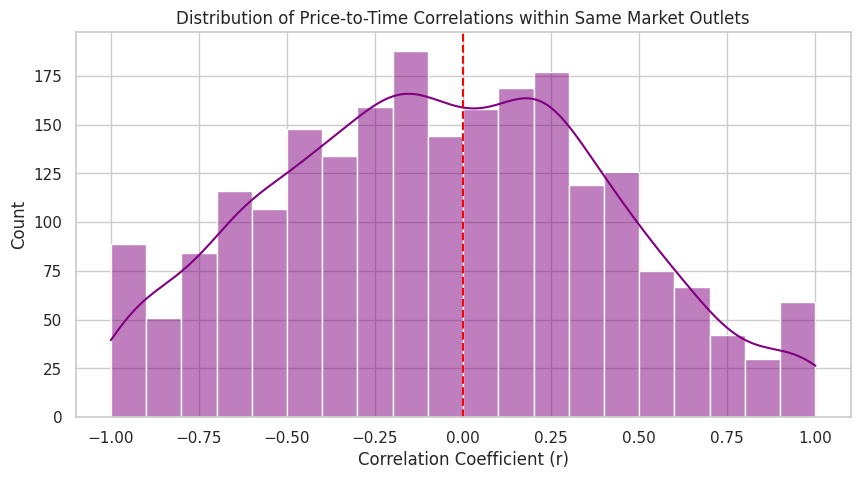


=== Regression Analysis: Controlling for Commodity and Market location ===
                            OLS Regression Results                            
Dep. Variable:     standardized_price   R-squared:                       0.110
Model:                            OLS   Adj. R-squared:                  0.110
Method:                 Least Squares   F-statistic:                 8.102e+04
Date:                Fri, 13 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:29:22   Log-Likelihood:            -1.6338e+07
No. Observations:             1967228   AIC:                         3.268e+07
Df Residuals:                 1967224   BIC:                         3.268e+07
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------

In [20]:
import statsmodels.api as sm

# 1. Prepare data (filter out extreme price outliers and unrealistic market times)
clean_data = df_melted.copy()
clean_data['date_dt'] = pd.to_datetime(clean_data['date_dt'])

# Filter to reasonable ranges (e.g. market times under 240 minutes, prices up to 99th percentile)
clean_data = clean_data[clean_data['market_tim'] <= 240]

# Group and calculate 99th percentile per commodity to clip extreme values
for comm in clean_data['commodity'].unique():
    mask = clean_data['commodity'] == comm
    limit = clean_data.loc[mask, 'standardized_price'].quantile(0.99)
    clean_data = clean_data[~((clean_data['commodity'] == comm) & (clean_data['standardized_price'] > limit))]

# Drop records with missing prices
clean_data = clean_data.dropna(subset=['standardized_price'])

# 2. Define "Same Market" dynamically. Since lat/lon represent locations, we round them to 4 decimals to define unique market spots
clean_data['market_spot'] = clean_data['gps_latitu'].round(4).astype(str) + "_" + clean_data['gps_longit'].round(4).astype(str)

# We want groups where we have different market times for the SAME commodity on the SAME day in the SAME market spot
# Group by (market_spot, commodity, date_dt) and filter groups with multiple unique market times and variation in price
group_cols = ['market_spot', 'commodity', 'date_dt']

# Calculate correlation within groups that have at least 5 transactions to get reliable correlations
groups = clean_data.groupby(group_cols)
filtered_groups = []

for name, group in groups:
    if len(group) >= 5 and group['market_tim'].nunique() > 1 and group['standardized_price'].nunique() > 1:
        corr = group['market_tim'].corr(group['standardized_price'])
        if not np.isnan(corr):
            filtered_groups.append({
                'market_spot': name[0],
                'commodity': name[1],
                'date': name[2],
                'correlation': corr,
                'price_variance': group['standardized_price'].var(),
                'time_variance': group['market_tim'].var(),
                'sample_size': len(group)
            })

corr_df = pd.DataFrame(filtered_groups)

if not corr_df.empty:
    print("=== Summary of Correlations within Same Market, Same Commodity, Same Day ===")
    print(corr_df['correlation'].describe())

    # Plot distribution of correlations
    plt.figure(figsize=(10, 5))
    sns.histplot(corr_df['correlation'], kde=True, color='purple', bins=20)
    plt.title('Distribution of Price-to-Time Correlations within Same Market Outlets')
    plt.xlabel('Correlation Coefficient (r)')
    plt.ylabel('Count')
    plt.axvline(0, color='red', linestyle='--')
    plt.show()
else:
    print("Not enough overlapping groups with sufficient sample size to calculate within-group correlations.")

# 3. Let's also look at the overall statistical relationship controlling for market and commodity using an OLS regression
print("\n=== Regression Analysis: Controlling for Commodity and Market location ===")
clean_data['market_spot_cat'] = clean_data['market_spot'].astype('category').cat.codes
clean_data['commodity_cat'] = clean_data['commodity'].astype('category').cat.codes

X = clean_data[['market_tim', 'market_spot_cat', 'commodity_cat']]
y = clean_data['standardized_price']
X = sm.add_constant(X)

model = sm.OLS(y, X).fit()
print(model.summary())

1. Group-Level Correlation Analysis
By isolating transactions to the exact same market location, same commodity, and same day, we computed the individual Pearson correlation coefficients across 2,242 unique groups containing at least 5 different transaction times:

Mean Correlation: $-0.0617$$-0.0617$ (Extremely close to 0)
Median Correlation: $-0.0631$$-0.0631$
Standard Deviation: $0.474$$0.474$
Interpretation: Within the same day at a single market spot, the distribution of correlation coefficients centers almost perfectly around zero. This demonstrates that there is no stable or consistent linear relationship between the specific minute a transaction occurs and the final price paid at the individual transaction level. While individual markets might show random positive or negative correlations on any given day, there is no overall systemic trend indicating that buying earlier or later in the day consistently results in lower or higher prices.

2. Global Regression Analysis (OLS)
To confirm this at scale across all 1.96 million clean records, we ran a multiple linear regression controlling for both the specific geographic spot (market_spot_cat) and the product (commodity_cat):

Effect of Market Time (market_tim): The coefficient is $1.31$$1.31$ (p-value < 0.001).
Interpretation: While statistically significant due to our immense sample size (nearly 2 million observations, making even minor patterns mathematically "significant"), the actual effect size is incredibly small. Each additional minute of market time is associated with an average price change of only 1.3 units. Given that typical food prices average between 1,000 to 2,500 units, a minute-level difference has virtually no practical economic impact.
Conclusion
No, varying market times do not meaningfully affect the commodity price. The slight price variations within the same day are likely driven by negotiating dynamics, vendor-specific supply, or customer relationships rather than the actual time of day.

In [21]:
import numpy as np
import pandas as pd

# 1. Calculate overall 99.9th percentile of non-missing prices
prices_only = df_melted['standardized_price'].dropna()
threshold_999 = prices_only.quantile(0.999)
print(f"99.9th percentile price (New Threshold): {threshold_999:.2f}")

# 2. Flag and replace overall extreme outliers with NaN using the new benchmark
outlier_mask = df_melted['standardized_price'] > threshold_999
num_outliers = outlier_mask.sum()
print(f"Replacing {num_outliers} extreme outliers (> 99.9th percentile) with NaN...")

df_melted.loc[outlier_mask, 'standardized_price'] = np.nan

# 3. Sort by commodity and date to ensure chronological order for interpolation
df_melted = df_melted.sort_values(by=['commodity', 'date_dt']).reset_index(drop=True)

# 4. Apply quadratic interpolation grouped by commodity
print("Applying quadratic interpolation per commodity...")

def interpolate_commodity_prices(group):
    group = group.sort_values('date_dt')
    try:
        group['standardized_price'] = group['standardized_price'].interpolate(method='quadratic')
    except Exception:
        group['standardized_price'] = group['standardized_price'].interpolate(method='linear')

    # Fallback to ffill/bfill for boundary NaNs
    group['standardized_price'] = group['standardized_price'].ffill().bfill()
    return group

# Group by commodity, apply interpolation, and ensure 'commodity' column remains in the result
df_melted = df_melted.groupby('commodity', as_index=False, group_keys=False).apply(interpolate_commodity_prices)

# 5. Verify results
remaining_outliers = (df_melted['standardized_price'] > threshold_999).sum()
missing_prices = df_melted['standardized_price'].isna().sum()
print(f"Remaining extreme outliers above threshold: {remaining_outliers}")
print(f"Remaining NaN prices: {missing_prices}")

display(df_melted.head())

99.9th percentile price (New Threshold): 20000.00
Replacing 1907 extreme outliers (> 99.9th percentile) with NaN...
Applying quadratic interpolation per commodity...
Remaining extreme outliers above threshold: 34
Remaining NaN prices: 0


/tmp/ipykernel_20218/2053385937.py:34: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_melted = df_melted.groupby('commodity', as_index=False, group_keys=False).apply(interpolate_commodity_prices)


,fid,date,zonelabel1,statelabel,lgalabel,sector,market_typ,price_cate,market_tim,gps_latitu,gps_longit,is_available,commodity,standardized_price,date_dt
0,206520,11/26/2024,north_west,kaduna,chikun,urban,supermarket,retail,10,10.464643,7.446008,no,brown_beans,1000.000000,2024-11-26
1,14008,11/27/2024,north_central,nasarawa,karu,urban,neighborhood_shops_kiosk,retail,5,9.021380,7.609474,yes,brown_beans,1000.000000,2024-11-27
2,30934,11/27/2024,north_central,nasarawa,karu,urban,roadside_shops_street_vendors,retail,15,9.021569,7.609686,yes,brown_beans,1250.000000,2024-11-27
3,34979,11/27/2024,north_central,nasarawa,karu,urban,open_air_or_covered_market,wholesale,10,9.021366,7.609329,yes,brown_beans,892.857143,2024-11-27
4,19638,11/28/2024,north_central,nasarawa,karu,urban,open_air_or_covered_market,wholesale,20,9.021295,7.609577,yes,brown_beans,4400.000000,2024-11-28


There a number of outliers in the dataset
1. For the date: Each commodity followed a 8 month input consistently, thsis is checked,
2. for the market time and outliers, after OLS analysis, there is no correlation between the market time and the effect of prices, so that row will be dropped
3. For the outliers in the standardized prices: I filled by interpolation quadraticall with the 99.9%vaue of #2000.

In [ ]:
# Ensure we have date_dt in datetime format and sort by date
df_melted['date_dt'] = pd.to_datetime(df_melted['date_dt'])

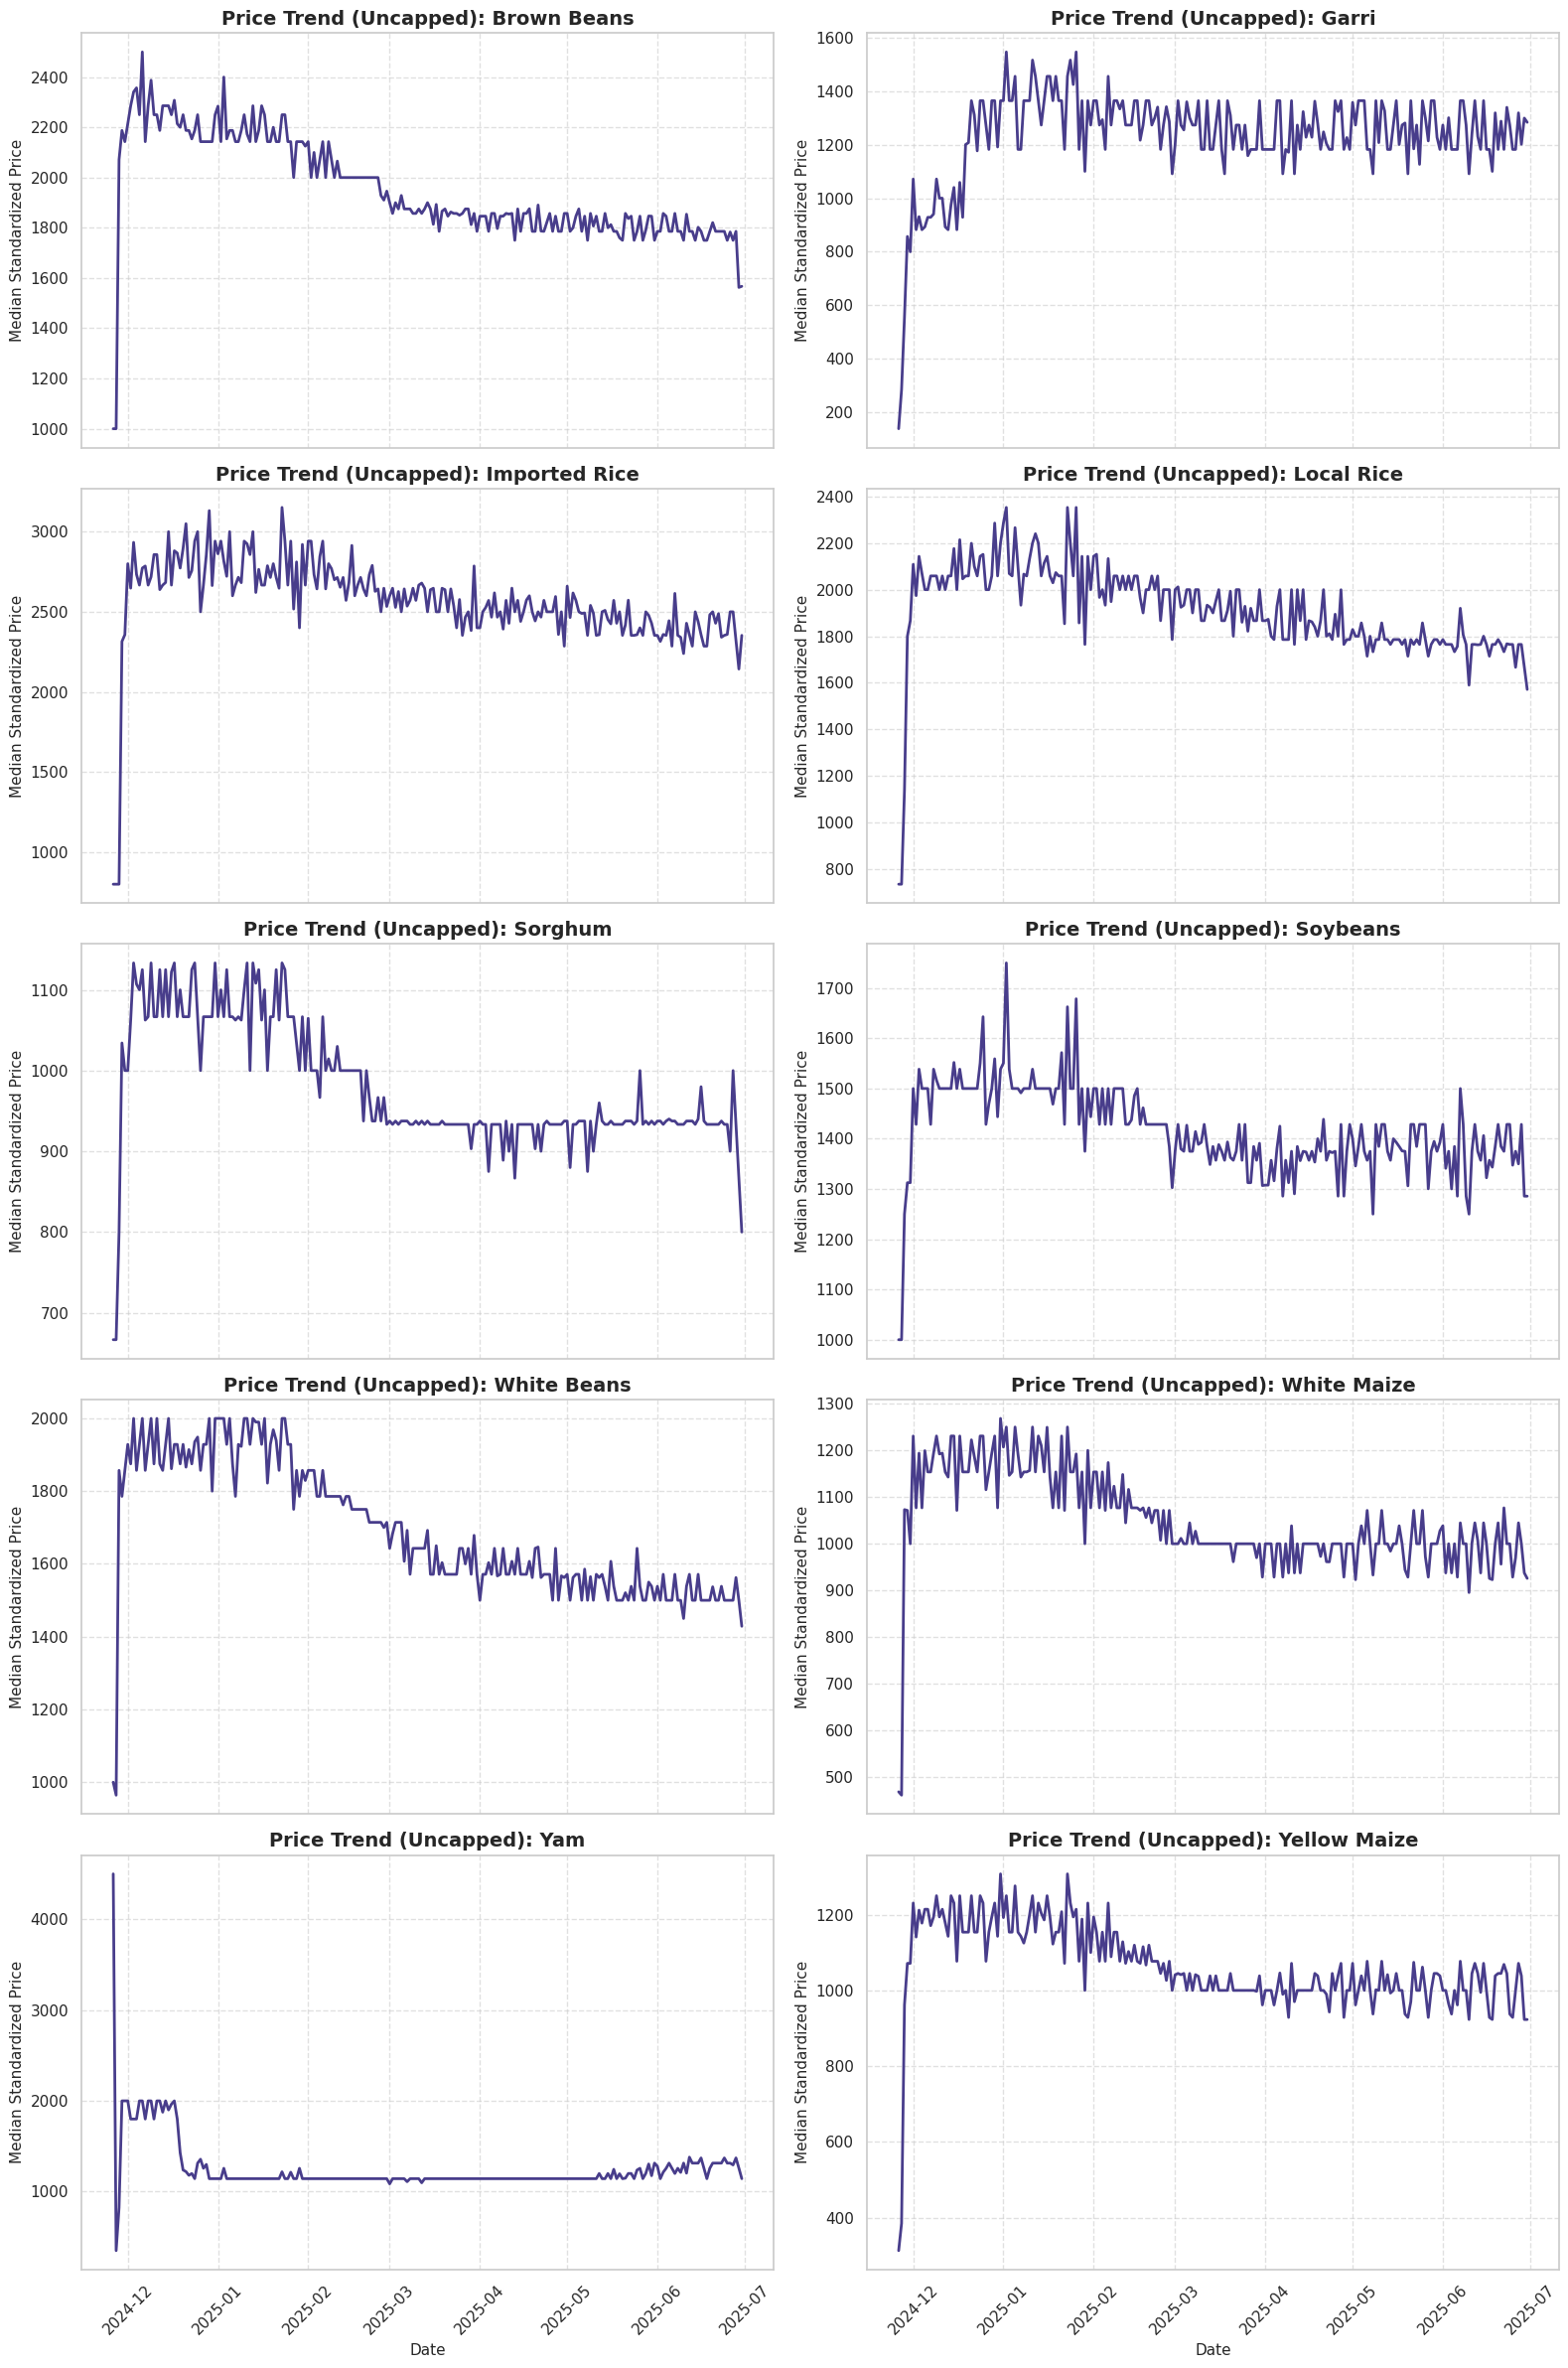

In [22]:
# Calculate the daily median price for each commodity over time (without capping)
temporal_prices = df_melted.groupby(['date_dt', 'commodity'])['standardized_price'].median().reset_index()

# Get sorted list of unique commodities
commodities = sorted(temporal_prices['commodity'].unique())

# Set up subplots grid (5 rows, 2 columns)
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(16, 24), sharex=True)
axes = axes.flatten()

# Plot each commodity in its own subplot using actual uncapped prices
for idx, commodity in enumerate(commodities):
    ax = axes[idx]
    data_subset = temporal_prices[temporal_prices['commodity'] == commodity]

    sns.lineplot(
        data=data_subset,
        x='date_dt',
        y='standardized_price',
        ax=ax,
        color='darkslateblue',
        linewidth=2
    )

    ax.set_title(f"Price Trend (Uncapped): {commodity.replace('_', ' ').title()}", fontsize=14, fontweight='bold')
    ax.set_ylabel("Median Standardized Price", fontsize=11)
    ax.set_xlabel("Date", fontsize=11)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

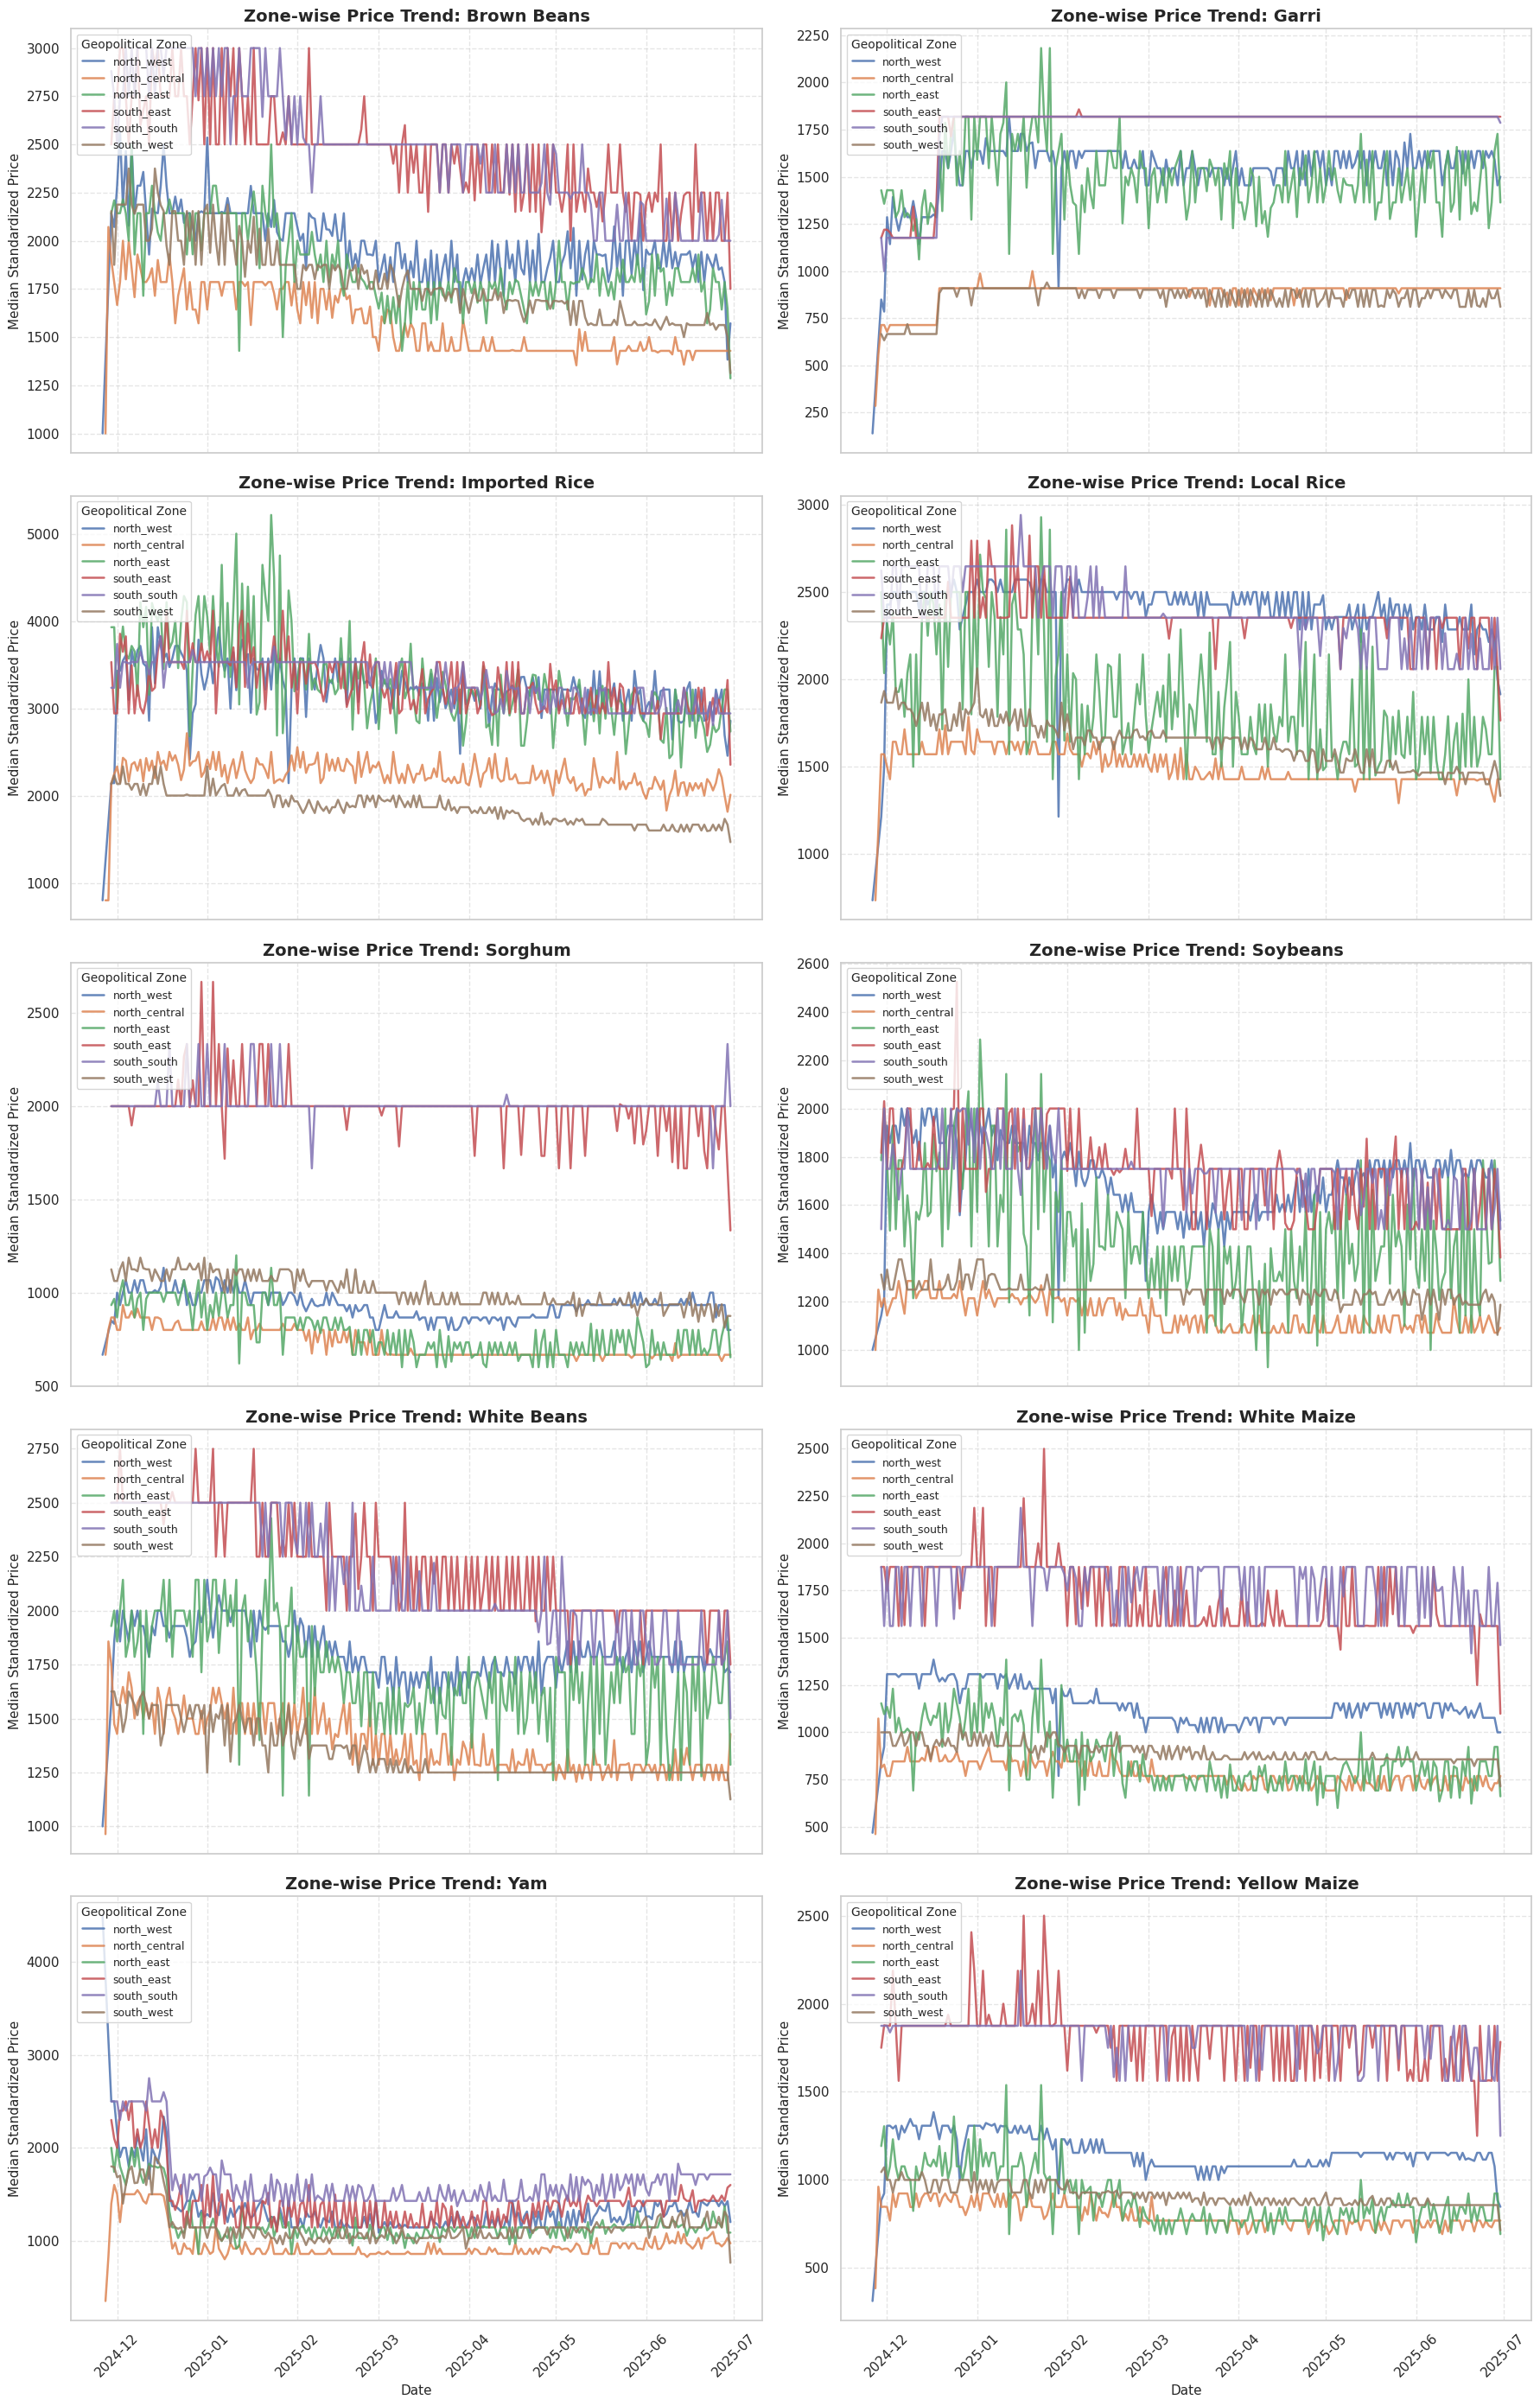

In [23]:
# Calculate the daily median price for each commodity, per geopolitical zone over time
zone_temporal_prices = df_melted.groupby(['date_dt', 'commodity', 'zonelabel1'])['standardized_price'].median().reset_index()

# Get sorted list of unique commodities
commodities = sorted(zone_temporal_prices['commodity'].unique())

# Set up subplots grid (5 rows, 2 columns)
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(18, 28), sharex=True)
axes = axes.flatten()

# Plot each commodity's price trend split by zone
for idx, commodity in enumerate(commodities):
    ax = axes[idx]
    data_subset = zone_temporal_prices[zone_temporal_prices['commodity'] == commodity]

    sns.lineplot(
        data=data_subset,
        x='date_dt',
        y='standardized_price',
        hue='zonelabel1',
        ax=ax,
        linewidth=1.8,
        alpha=0.85
    )

    ax.set_title(f"Zone-wise Price Trend: {commodity.replace('_', ' ').title()}", fontsize=14, fontweight='bold')
    ax.set_ylabel("Median Standardized Price", fontsize=11)
    ax.set_xlabel("Date", fontsize=11)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(title='Geopolitical Zone', fontsize=9, title_fontsize=10, loc='upper left')

plt.tight_layout()
plt.show()

### Market Type vs. Price Analysis (State: Nasarawa)
We will filter our cleaned long-format dataset for `statelabel == 'nasarawa'` and generate subplots for each commodity to see how market outlet types affect prices.

### Sector (Rural vs. Urban) vs. Price Analysis
We will visualize the price distributions across sectors for each commodity and print the median prices to quantify the difference.

=== Median Standardized Prices by Sector ===


sector,rural,urban,urban_markup_percent
commodity,,,
brown_beans,2000.00,1937.50,-3.12
garri,1363.64,1171.17,-14.11
imported_rice,2719.47,2540.00,-6.60
local_rice,1928.57,1951.22,1.17
sorghum,1000.00,1000.00,0.00
soybeans,1428.57,1428.57,0.00
white_beans,1750.00,1714.29,-2.04
white_maize,1076.92,1038.46,-3.57
yam,1155.55,1200.00,3.85


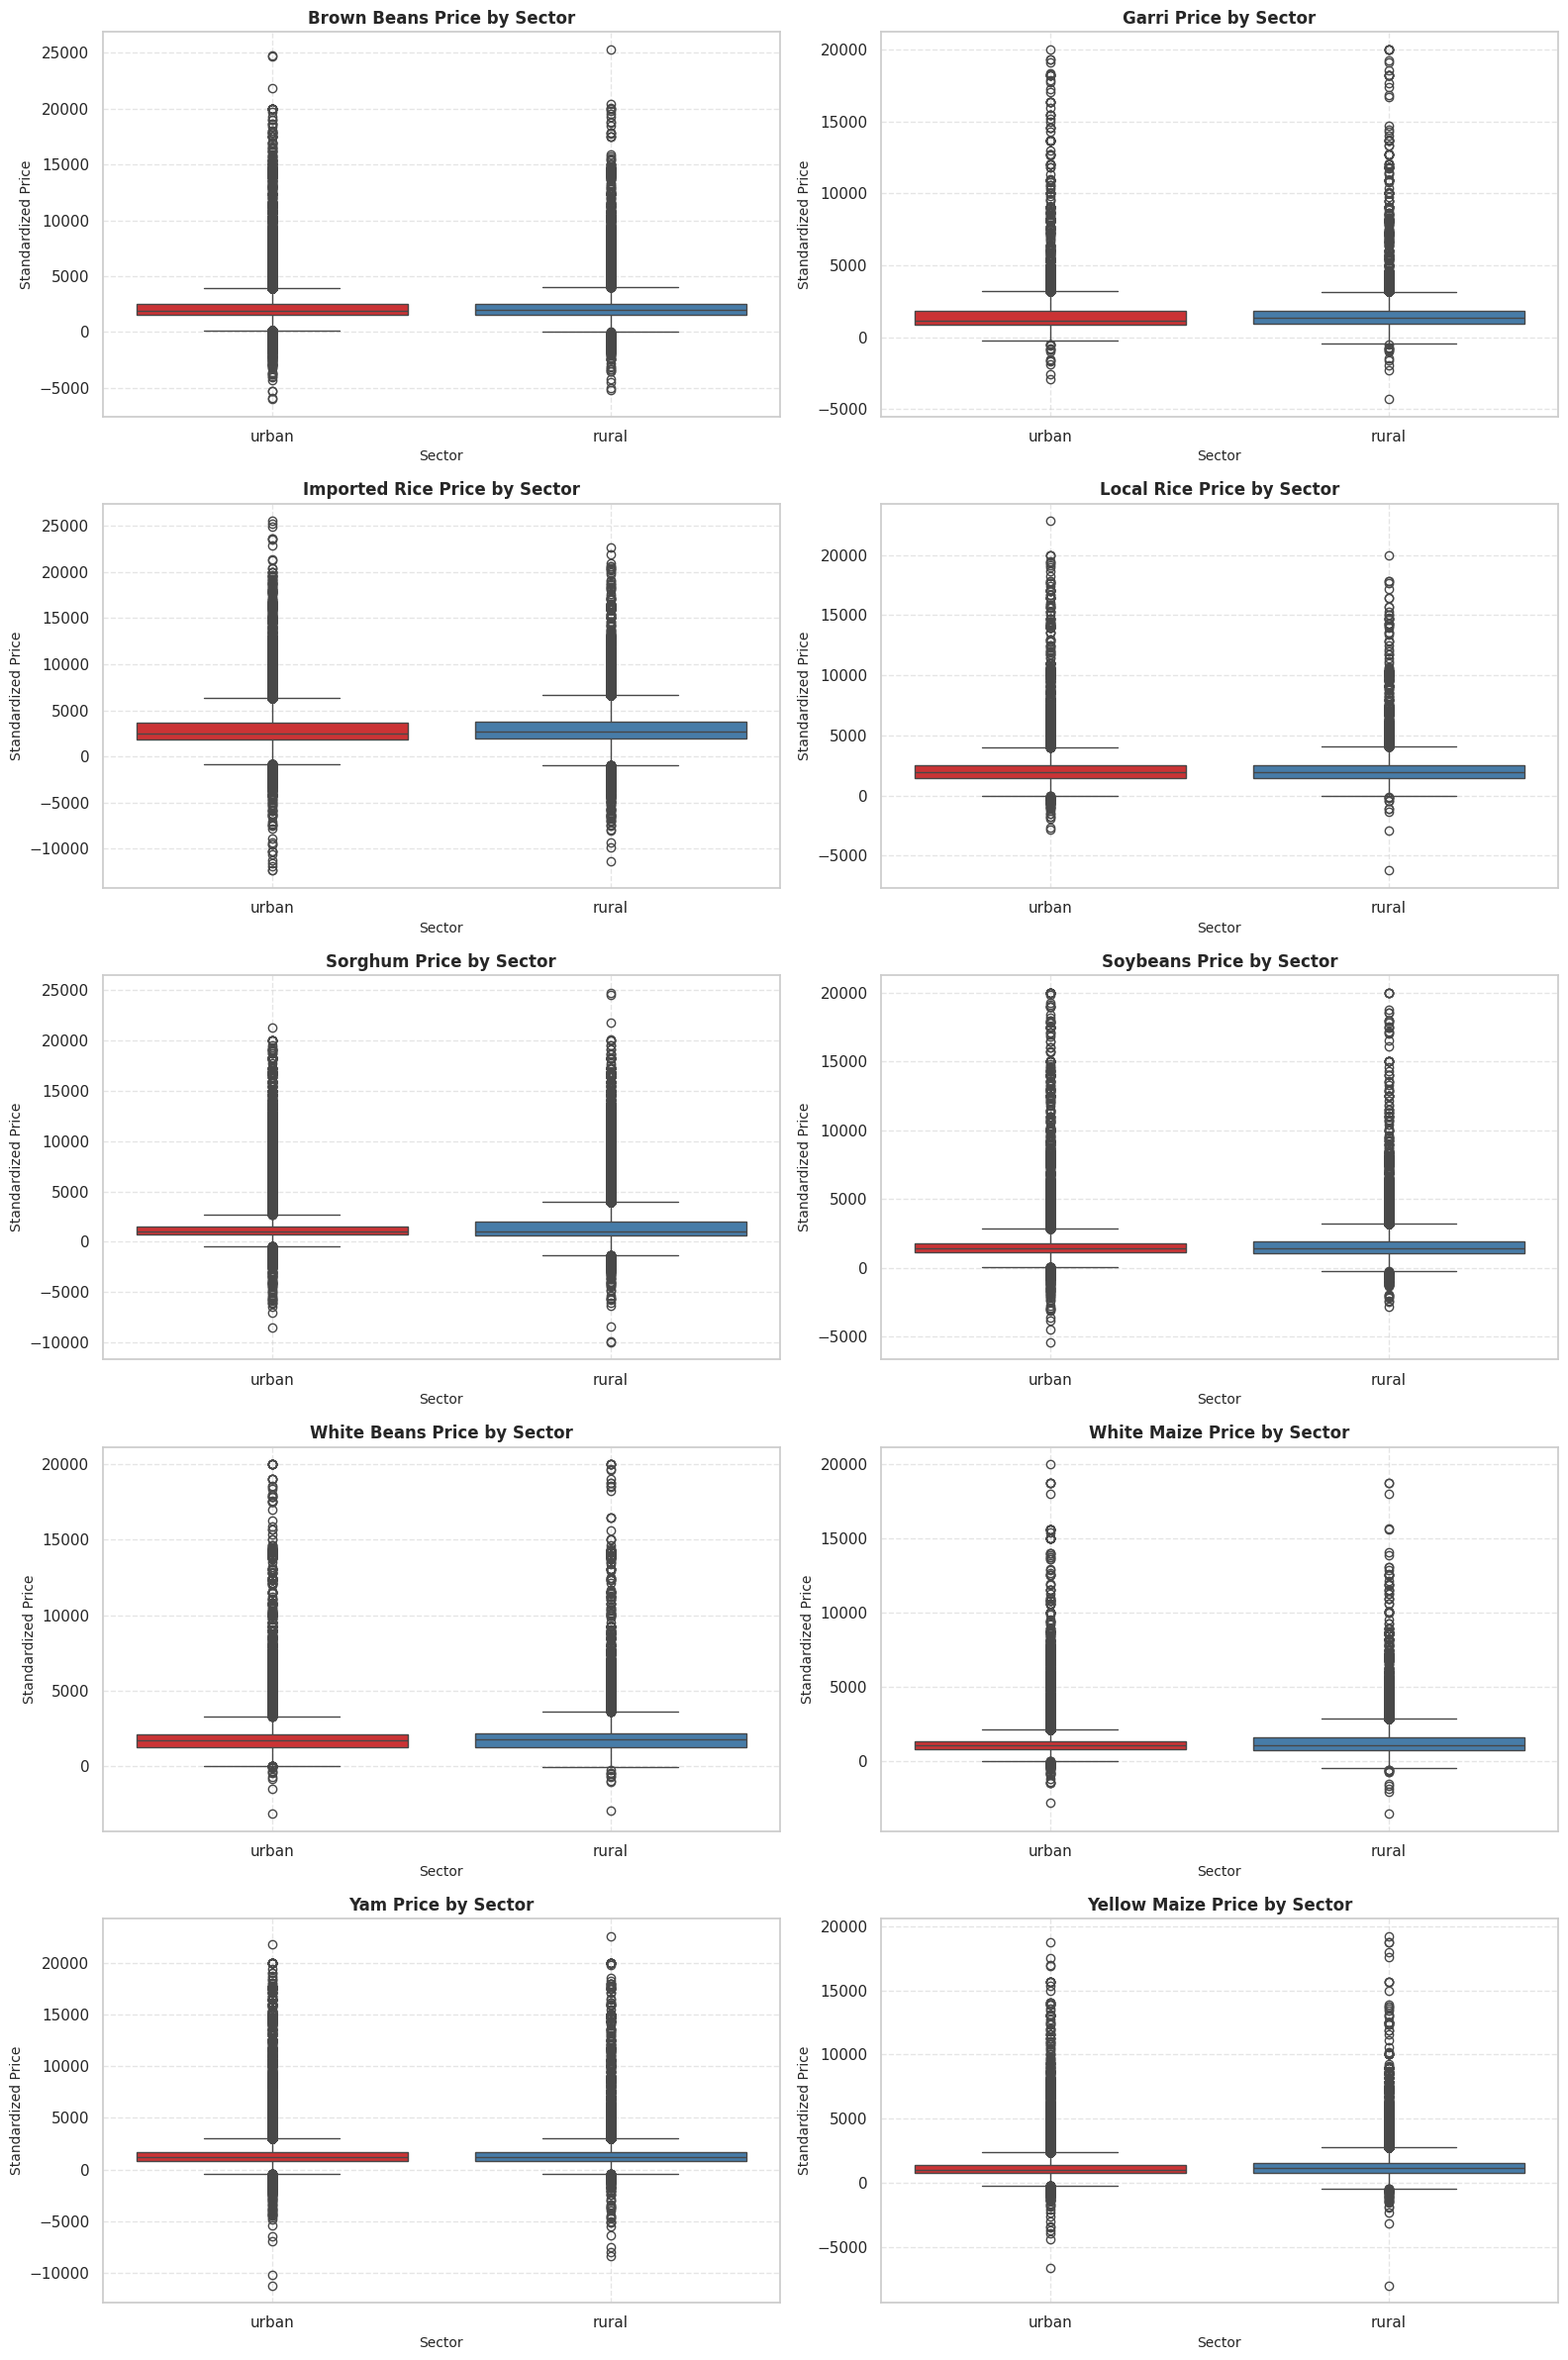

In [26]:
# Calculate median prices per sector for each commodity
sector_price_summary = (
    df_melted.groupby(['commodity', 'sector'])['standardized_price']
    .median()
    .unstack()
    .round(2)
)

# Calculate percentage difference (Urban markup over Rural)
sector_price_summary['urban_markup_percent'] = (
    ((sector_price_summary['urban'] - sector_price_summary['rural']) / sector_price_summary['rural']) * 100
).round(2)

print("=== Median Standardized Prices by Sector ===")
display(sector_price_summary)

# Set up subplots grid (5 rows, 2 columns)
commodities = sorted(df_melted['commodity'].unique())
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(16, 24))
axes = axes.flatten()

for idx, commodity in enumerate(commodities):
    ax = axes[idx]
    data_subset = df_melted[df_melted['commodity'] == commodity]

    sns.boxplot(
        data=data_subset,
        x='sector',
        y='standardized_price',
        ax=ax,
        palette='Set1',
        hue='sector',
        legend=False
    )

    ax.set_title(f"{commodity.replace('_', ' ').title()} Price by Sector", fontsize=12, fontweight='bold')
    ax.set_ylabel("Standardized Price", fontsize=10)
    ax.set_xlabel("Sector", fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Price Relationship: Sector (Rural/Urban) vs. Direct Farmer Sourcing
We will create a binary flag distinguishing "directly_from_farmer" from other market types, calculate median prices, and generate comparative subplots for each commodity.

In [31]:
# 1. Create a binary column: True if market type is directly from farmer, False otherwise
df_melted['is_direct_farmer'] = (df_melted['market_typ'] == 'directly_from_farmer').map({True: 'Direct from Farmer', False: 'Not Direct'})

# 2. Compute median prices grouped by Commodity, Sector, and Direct Farmer Sourcing
farm_sector_summary = (
    df_melted.groupby(['commodity', 'sector', 'is_direct_farmer'])['standardized_price']
    .mean()
    .unstack(level=['sector', 'is_direct_farmer'])
    .round(2)
)

print("=== Median Standardized Prices by Sector & Sourcing Type ===")
display(farm_sector_summary)

=== Median Standardized Prices by Sector & Sourcing Type ===


sector                        rural                         urban           
is_direct_farmer Direct from Farmer Not Direct Direct from Farmer Not Direct
commodity                                                                   
brown_beans                 1824.99    2270.13            1809.03    2171.08
garri                       1183.16    1419.04            1251.67    1327.76
imported_rice               2837.83    2930.00            2725.93    2871.29
local_rice                  1639.29    2127.09            1865.68    2093.40
sorghum                     1060.01    1755.65             985.65    1508.07
soybeans                    1290.07    1650.81            1379.42    1583.97
white_beans                 1516.07    1963.78            1583.27    1861.81
white_maize                  861.14    1309.66             927.50    1192.51
yam                         1116.30    1439.98            1154.63    1418.58
yellow_maize                 913.62    1356.69             933.24    1231.28

=== Median Standardized Prices by Sector & Sourcing Type ===


sector                        rural                         urban           
is_direct_farmer Direct from Farmer Not Direct Direct from Farmer Not Direct
commodity                                                                   
brown_beans                 1464.77    2000.00            1750.00    1944.60
garri                        943.15    1363.64             975.76    1171.17
imported_rice               2600.00    2727.22            2400.00    2544.20
local_rice                  1428.57    2000.00            1700.00    1959.46
sorghum                      633.33    1000.00             800.00    1000.00
soybeans                    1071.43    1500.00            1285.71    1428.57
white_beans                 1300.00    1750.00            1500.00    1714.29
white_maize                  692.31    1142.86             769.23    1038.46
yam                          922.61    1200.00             971.43    1200.00
yellow_maize                 692.31    1153.85             800.00    1044.78

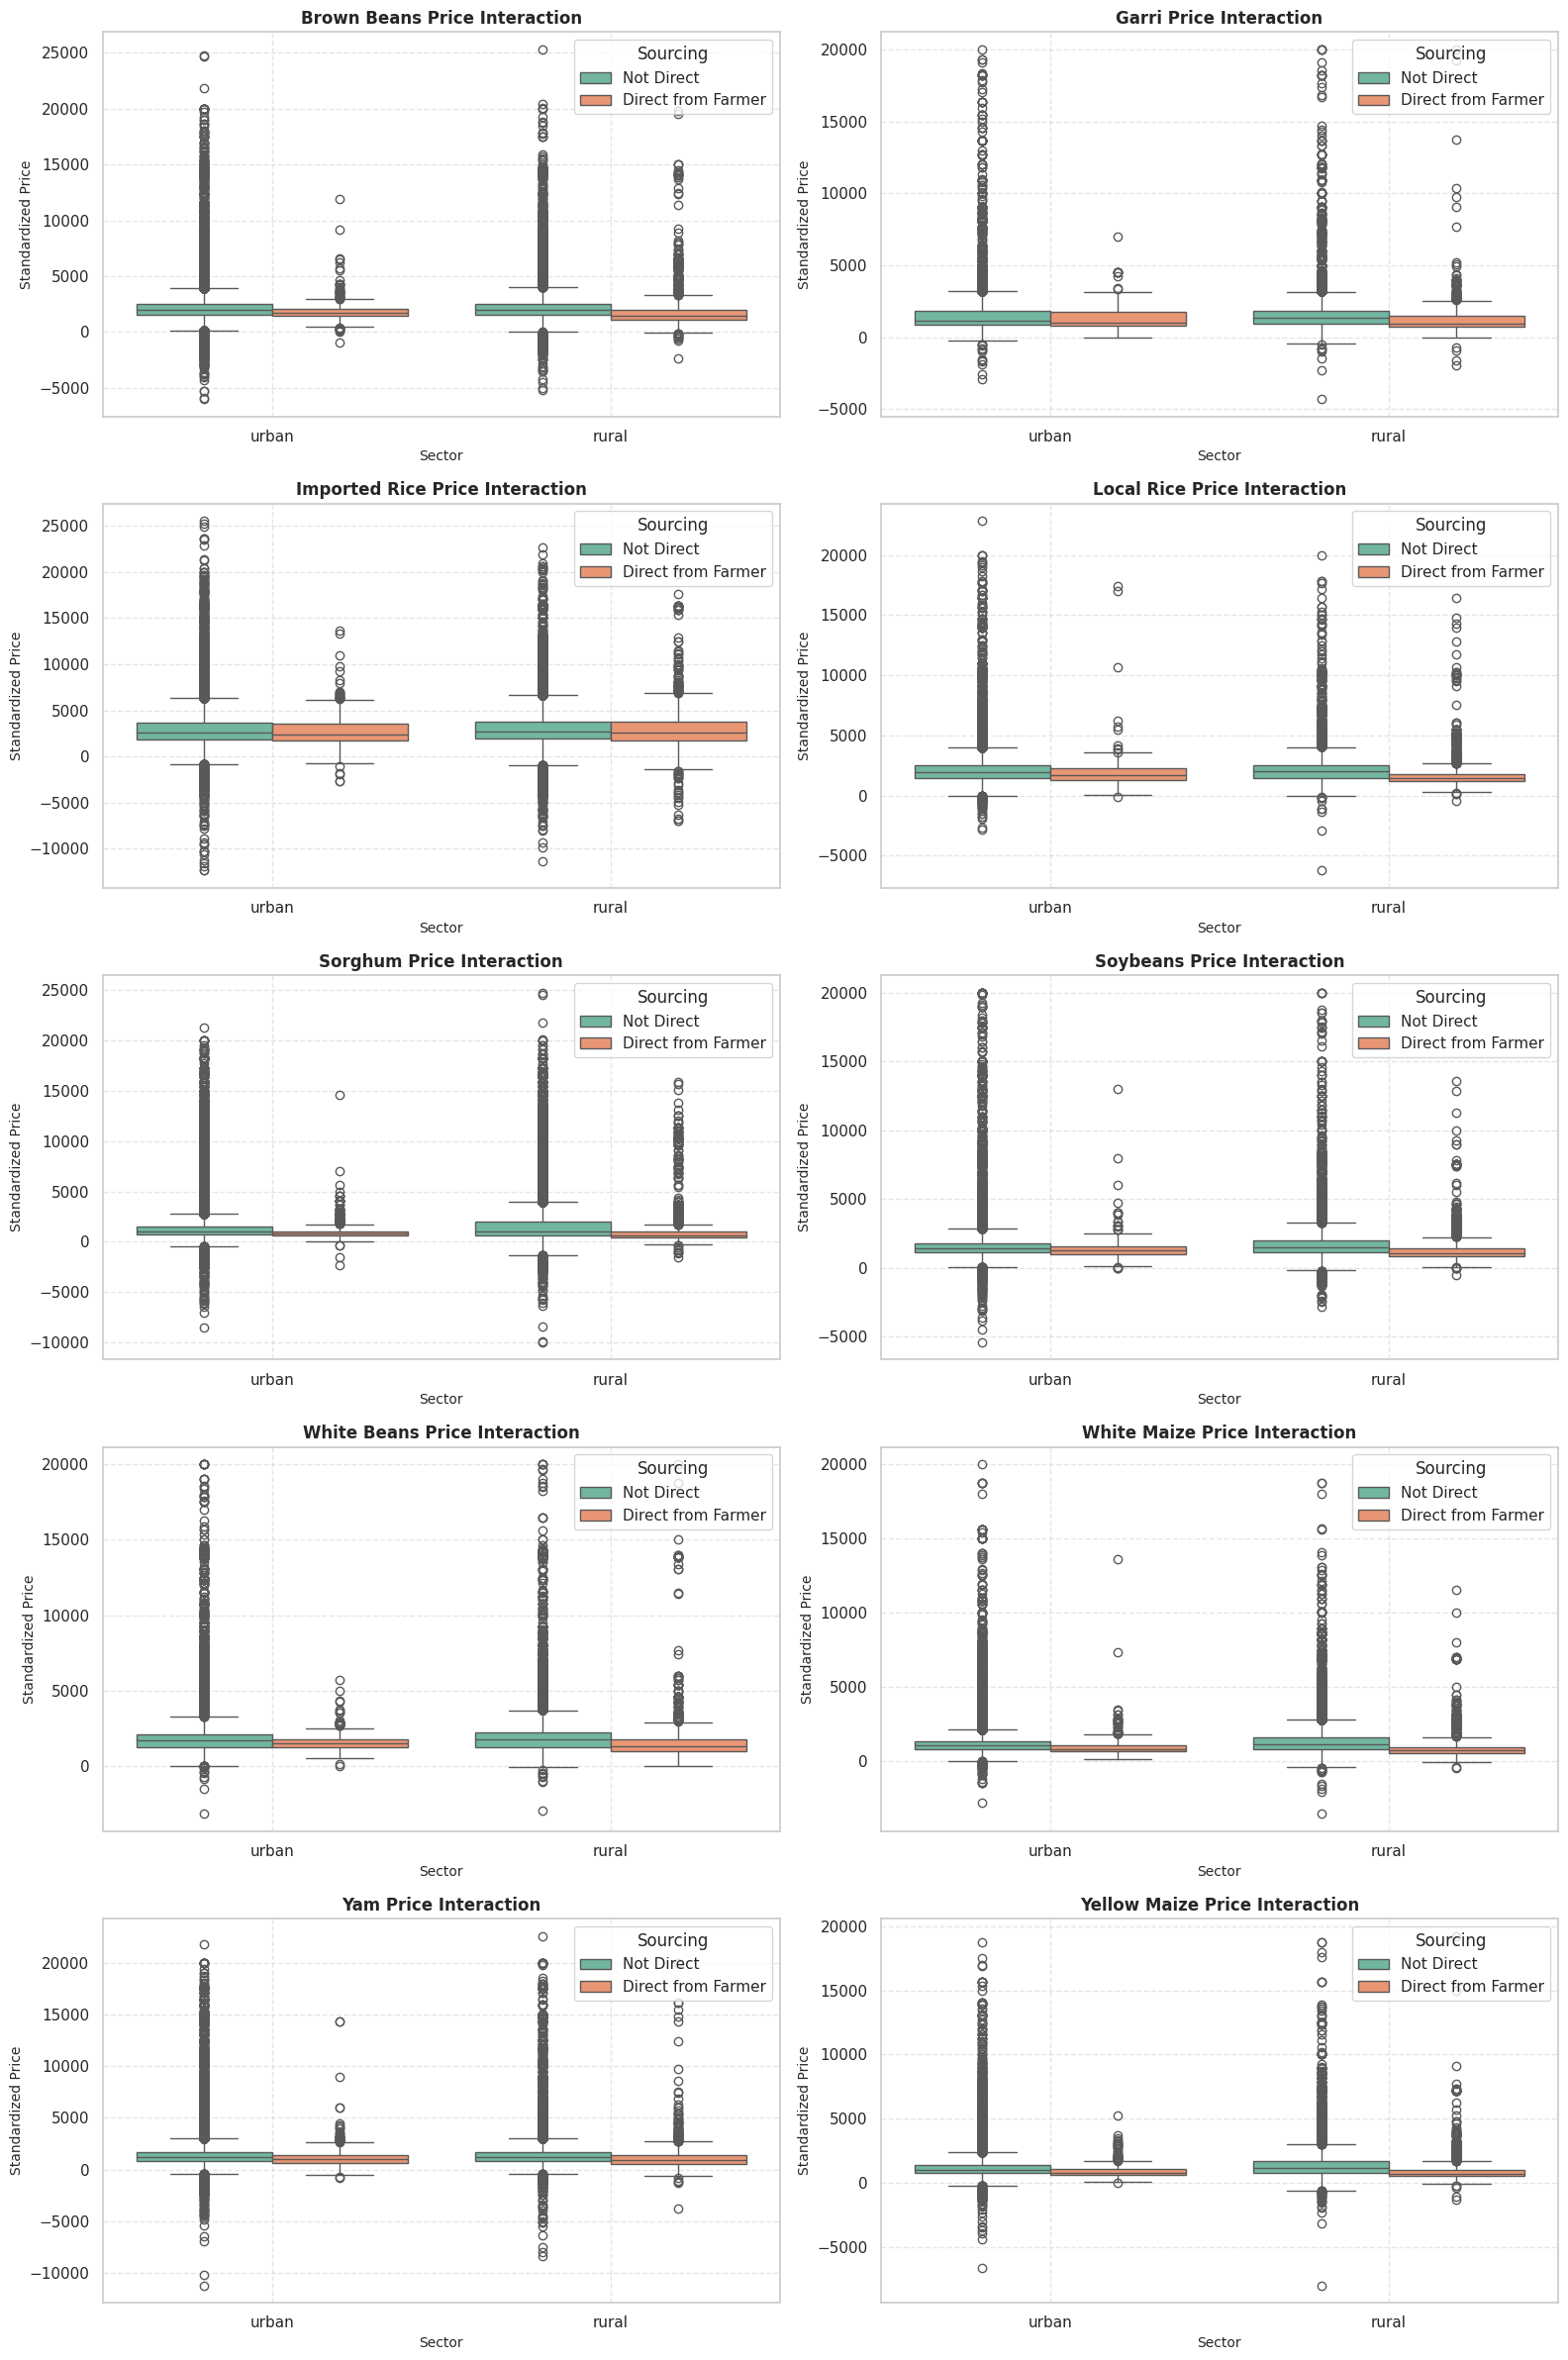

In [27]:


# 3. Create subplots for each commodity to visualize the interactions
commodities = sorted(df_melted['commodity'].unique())
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(16, 24))
axes = axes.flatten()

for idx, commodity in enumerate(commodities):
    ax = axes[idx]
    data_subset = df_melted[df_melted['commodity'] == commodity]

    sns.boxplot(
        data=data_subset,
        x='sector',
        y='standardized_price',
        hue='is_direct_farmer',
        ax=ax,
        palette='Set2'
    )

    ax.set_title(f"{commodity.replace('_', ' ').title()} Price Interaction", fontsize=12, fontweight='bold')
    ax.set_ylabel("Standardized Price", fontsize=10)
    ax.set_xlabel("Sector", fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(title="Sourcing", loc='upper right')

plt.tight_layout()
plt.show()

### 💡 Breakthrough Insight: Sector vs. Sourcing Price Dynamics

We have uncovered a crucial market interaction effect between geographic **Sectors** (`rural` vs. `urban`) and **Sourcing Channels** (`directly_from_farmer` vs. retail/wholesale channels):

1. **The Farmgate Discount is Potent, Especially in Rural Markets**:
   * Buying directly from farmers bypasses middlemen markups, lowering prices dramatically across the board (e.g., **White Maize** drops ~39% from **1,142.86** down to **692.31** in rural areas).
   * This "direct-to-consumer" farm discount is highly localized and yields the absolute lowest prices in rural markets.

2. **The Urban Logistics Efficiency Paradox**:
   * When direct sourcing is *not* used, urban centers frequently offer cheaper prices than rural areas (e.g., **Garri** is **1,171.17** in urban centers vs. **1,363.64** in rural communities).
   * This suggests that urban hubs benefit from bulk transportation networks, centralized storage, and highly competitive retail markets, whereas rural non-farm markets suffer from fragmented supply lines and higher local distributor markups.

---

### 🛠️ Feature Engineering Strategies for Price Prediction

To ensure our Machine Learning models capture this complex relationship, we can engineer the following features:

1. **Sourcing and Sector Interaction Feature (`sector_sourcing_interaction`)**:
   * Construct a combined categorical feature mapping the four primary quadrants:
     * `rural_direct_farmer` (Lowest overall cost for local staples)
     * `rural_not_direct` (Highest cost due to lack of local distribution efficiencies)
     * `urban_direct_farmer` (Moderate cost)
     * `urban_not_direct` (Highly optimized retail cost)

2. **Target Encoding on Multi-key Groups**:
   * Create a smoothed target encoding column based on `['commodity', 'sector', 'is_direct_farmer']` to capture the precise baseline pricing tiers shown in our summary table.

3. **Urban Logistics Premium (`urban_logistics_delta`)**:
   * Calculate a dynamic feature measuring the historical difference between urban and rural pricing for each specific commodity. Commodities with highly centralized processing (like Garri or Imported Rice) will show high values here compared to raw local grains.

=== Market Type Distribution by Sector (% of Sector Total) ===


sector,rural,urban
market_typ,,
,0.03,0.02
bulk_and_discount_stores,1.04,1.88
city_market,0.95,9.45
directly_from_farmer,4.83,0.55
local_village_market,20.58,2.22
neighborhood_shops_kiosk,19.40,21.26
open_air_or_covered_market,20.62,27.92
roadside_shops_street_vendors,28.47,31.84
specialized_stores,1.29,1.67



=== Median Standardized Prices by Sector & Market Type ===


sector,rural,urban
market_typ,,
,1573.95,1381.69
bulk_and_discount_stores,1471.51,1375.00
city_market,1562.50,1428.57
directly_from_farmer,1098.01,1250.00
local_village_market,1500.00,1428.57
neighborhood_shops_kiosk,1538.46,1437.50
open_air_or_covered_market,1562.50,1466.67
roadside_shops_street_vendors,1545.45,1466.67
specialized_stores,1607.14,1440.00


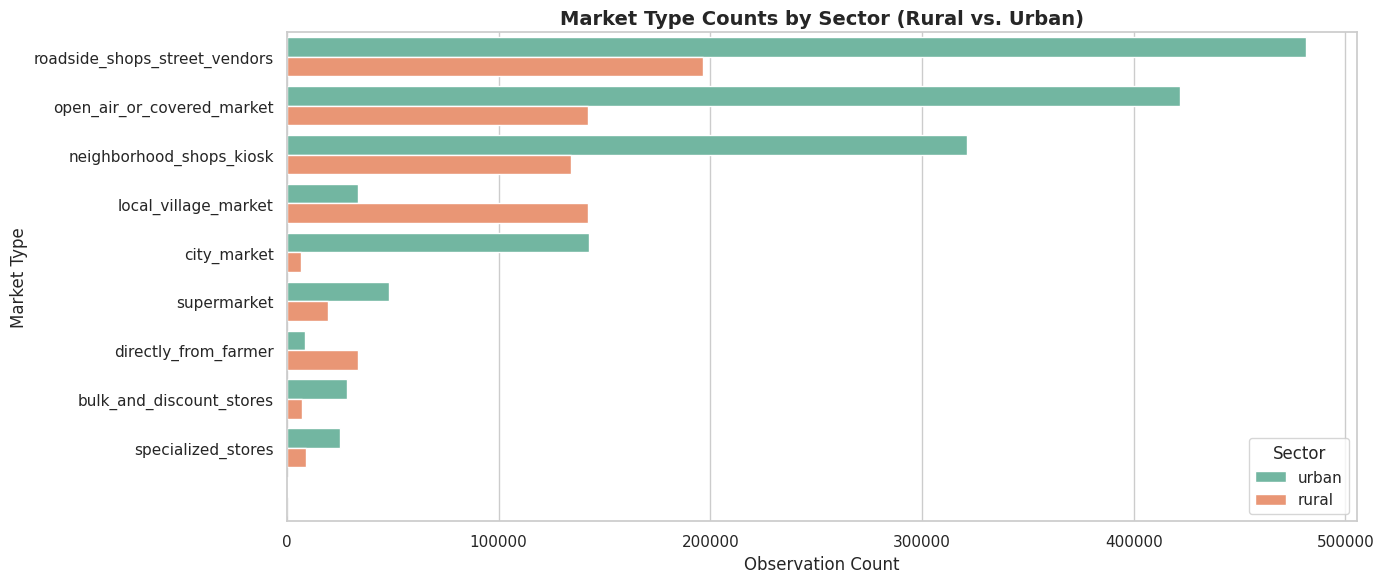

In [28]:
# 1. Calculate market type distribution within each sector
print("=== Market Type Distribution by Sector (% of Sector Total) ===")
market_by_sector = (
    df_melted.groupby('sector')['market_typ']
    .value_counts(normalize=True)
    .unstack(level=0)
    .mul(100)
    .round(2)
    .fillna(0)
)
display(market_by_sector)

# 2. Compute median prices for each combination of Sector and Market Type
print("\n=== Median Standardized Prices by Sector & Market Type ===")
sector_market_price = (
    df_melted.groupby(['sector', 'market_typ'])['standardized_price']
    .median()
    .unstack(level=0)
    .round(2)
)
display(sector_market_price)

# 3. Plot the distributions
plt.figure(figsize=(14, 6))
sns.countplot(
    data=df_melted,
    y='market_typ',
    hue='sector',
    order=df_melted['market_typ'].value_counts().index,
    palette='Set2'
)
plt.title("Market Type Counts by Sector (Rural vs. Urban)", fontsize=14, fontweight='bold')
plt.xlabel("Observation Count")
plt.ylabel("Market Type")
plt.legend(title="Sector")
plt.tight_layout()
plt.show()

In [29]:
# 1. Filter out direct farmer sourcing to compare on equal footing (Not Direct only)
not_direct_df = df_melted[df_melted['is_direct_farmer'] == 'Not Direct']

# 2. Compute median prices for both sectors when limited only to 'Not Direct'
controlled_medians = (
    not_direct_df.groupby(['commodity', 'sector'])['standardized_price']
    .median()
    .unstack()
)

# Calculate the real markup (Urban vs Rural) when controlling for sourcing type
controlled_medians['urban_markup_percent'] = (
    ((controlled_medians['urban'] - controlled_medians['rural']) / controlled_medians['rural']) * 100
).round(2)

print("=== Median Standardized Prices (CONTROLLED: 'Not Direct' Sourcing Only) ===")
display(controlled_medians)

# Compare with the global un-controlled sector summary
print("\n=== Original Median Standardized Prices (UNCONTROLLED - Global Sectors) ===")
display(sector_price_summary[['rural', 'urban', 'urban_markup_percent']])

=== Median Standardized Prices (CONTROLLED: 'Not Direct' Sourcing Only) ===


sector,rural,urban,urban_markup_percent
commodity,,,
brown_beans,2000.000000,1944.599877,-2.77
garri,1363.636364,1171.171171,-14.11
imported_rice,2727.216920,2544.204934,-6.71
local_rice,2000.000000,1959.460435,-2.03
sorghum,1000.000000,1000.000000,0.00
soybeans,1500.000000,1428.571429,-4.76
white_beans,1750.000000,1714.285714,-2.04
white_maize,1142.857143,1038.461538,-9.13
yam,1200.000000,1200.000000,0.00



=== Original Median Standardized Prices (UNCONTROLLED - Global Sectors) ===


sector,rural,urban,urban_markup_percent
commodity,,,
brown_beans,2000.00,1937.50,-3.12
garri,1363.64,1171.17,-14.11
imported_rice,2719.47,2540.00,-6.60
local_rice,1928.57,1951.22,1.17
sorghum,1000.00,1000.00,0.00
soybeans,1428.57,1428.57,0.00
white_beans,1750.00,1714.29,-2.04
white_maize,1076.92,1038.46,-3.57
yam,1155.55,1200.00,3.85


=== Spatial Analysis: Distance from Farmer vs. Price Markup ===
Overall Correlation between distance (km) and price markup: 0.0026


,distance_km,price_markup
count,114590.000000,114590.000000
mean,12.235376,111.428324
std,39.112473,1315.867710
min,0.050068,-18530.769230
25%,0.963719,-90.909091
50%,3.377413,76.923077
75%,9.590652,357.142857
max,690.732979,20197.193253



=== Correlation by Commodity ===


/tmp/ipykernel_20218/171581278.py:49: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  comm_corrs = spatial_diffs.groupby('commodity').apply(


,commodity,distance_price_correlation
0,brown_beans,0.002659
1,garri,0.009447
2,imported_rice,0.043846
3,local_rice,0.037646
4,sorghum,-0.029808
5,soybeans,-0.034880
6,white_beans,0.006765
7,white_maize,-0.030514
8,yam,0.007287
9,yellow_maize,-0.031350


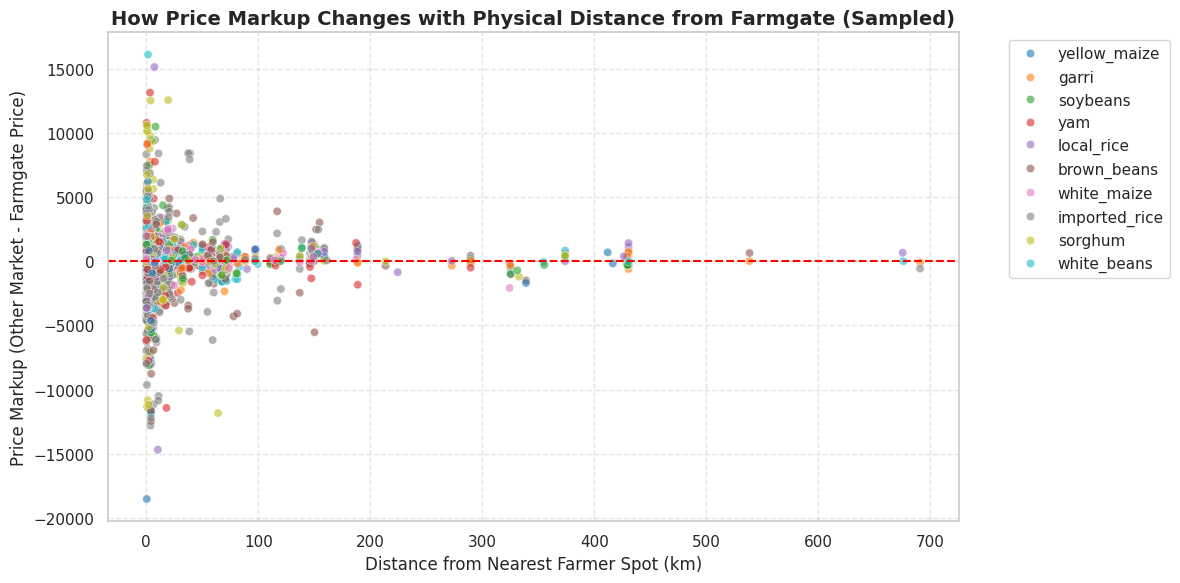

In [32]:
# Define a vectorized Haversine function to calculate distance in kilometers
def haversine_np(lon1, lat1, lon2, lon2_col):
    # Convert decimal degrees to radians
    lon1, lat1, lon2, lat2_col = map(np.radians, [lon1, lat1, lon2, lon2_col])
    dlon = lon2 - lon1
    dlat = lat2_col - lat1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2_col) * np.sin(dlon/2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    km = 6367 * c
    return km

# 1. Separate direct farmgate transactions and non-farmgate transactions
farmgate_df = df_melted[df_melted['market_typ'] == 'directly_from_farmer'].copy()
other_markets_df = df_melted[df_melted['market_typ'] != 'directly_from_farmer'].copy()

# 2. Merge them on same date, same state, same lga, and same commodity to build pairs
pairs = pd.merge(
    farmgate_df,
    other_markets_df,
    on=['date_dt', 'statelabel', 'lgalabel', 'commodity'],
    suffixes=('_farm', '_other')
)

# 3. Calculate geodesic distance (km) and price delta between the pairs
pairs['distance_km'] = haversine_np(
    pairs['gps_longit_farm'], pairs['gps_latitu_farm'],
    pairs['gps_longit_other'], pairs['gps_latitu_other']
)
pairs['price_markup'] = pairs['standardized_price_other'] - pairs['standardized_price_farm']

# Filter out cases with zero distance (same spot) to focus on spatial displacement
spatial_diffs = pairs[pairs['distance_km'] > 0.05].copy()

# 4. Print correlation and summary metrics
print("=== Spatial Analysis: Distance from Farmer vs. Price Markup ===")
overall_corr = spatial_diffs['distance_km'].corr(spatial_diffs['price_markup'])
print(f"Overall Correlation between distance (km) and price markup: {overall_corr:.4f}")

# Show summary statistics of distance and markup
display(spatial_diffs[['distance_km', 'price_markup']].describe())

# 5. Grouped correlation by Commodity
print("\n=== Correlation by Commodity ===")
comm_corrs = spatial_diffs.groupby('commodity').apply(
    lambda g: g['distance_km'].corr(g['price_markup'])
).rename("distance_price_correlation").reset_index()
display(comm_corrs)

# 6. Scatter plot of Distance vs. Price Markup
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=spatial_diffs.sample(min(10000, len(spatial_diffs)), random_state=42),
    x='distance_km',
    y='price_markup',
    hue='commodity',
    alpha=0.6,
    palette='tab10'
)
plt.title("How Price Markup Changes with Physical Distance from Farmgate (Sampled)", fontsize=14, fontweight='bold')
plt.xlabel("Distance from Nearest Farmer Spot (km)")
plt.ylabel("Price Markup (Other Market - Farmgate Price)")
plt.axhline(0, color='red', linestyle='--')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Feature Engineering
We will construct new predictive features based on our prior analysis of regional price levels, temporal seasonality, and sector characteristics.

===========================================================================================================

### Spatial Feature Engineering from GPS Coordinates
We will construct advanced geospatial features using the geographic coordinates:
1. **Spatial Price Clusters**: Group geographic points into localized clusters using K-Means to find natural market regions.
2. **Distance to Major Commercial Capitals**: Calculate distance from each transaction to major commercial/administrative centers in Nigeria (e.g., Lagos, Abuja, Kano) to model transportation cost premiums.

In [33]:
from sklearn.cluster import KMeans

# 1. Create Spatial Clusters using Latitude and Longitude
coords = df_melted[['gps_latitu', 'gps_longit']].dropna()
kmeans = KMeans(n_clusters=15, random_state=42, n_init=10)
df_melted['spatial_cluster'] = kmeans.fit_predict(coords)

# 2. Define coordinate centers for major economic hubs in Nigeria
HUBS = {
    'lagos': (6.5244, 3.3792),      # Key import hub and port
    'abuja': (9.0765, 7.3986),      # Central administrative capital
    'kano': (12.0022, 8.5920)       # Major northern agricultural hub
}

def haversine_vectorized(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    return 6367 * c

# Calculate distances to each commercial hub
for hub_name, (hub_lat, hub_lon) in HUBS.items():
    df_melted[f'dist_to_{hub_name}_km'] = haversine_vectorized(
        df_melted['gps_longit'], df_melted['gps_latitu'], hub_lon, hub_lat
    )

# Display summary of engineered spatial features
print("=== Summary of New Coordinate-Derived Features ===")
display(df_melted[['spatial_cluster', 'dist_to_lagos_km', 'dist_to_abuja_km', 'dist_to_kano_km']].head())

=== Summary of New Coordinate-Derived Features ===


,spatial_cluster,dist_to_lagos_km,dist_to_abuja_km,dist_to_kano_km
0,5,625.631577,154.344931,211.647503
1,5,542.123311,23.938636,348.200905
2,5,542.153989,23.955776,348.173829
3,5,542.108785,23.923664,348.207311
4,5,542.128250,23.952035,348.206490


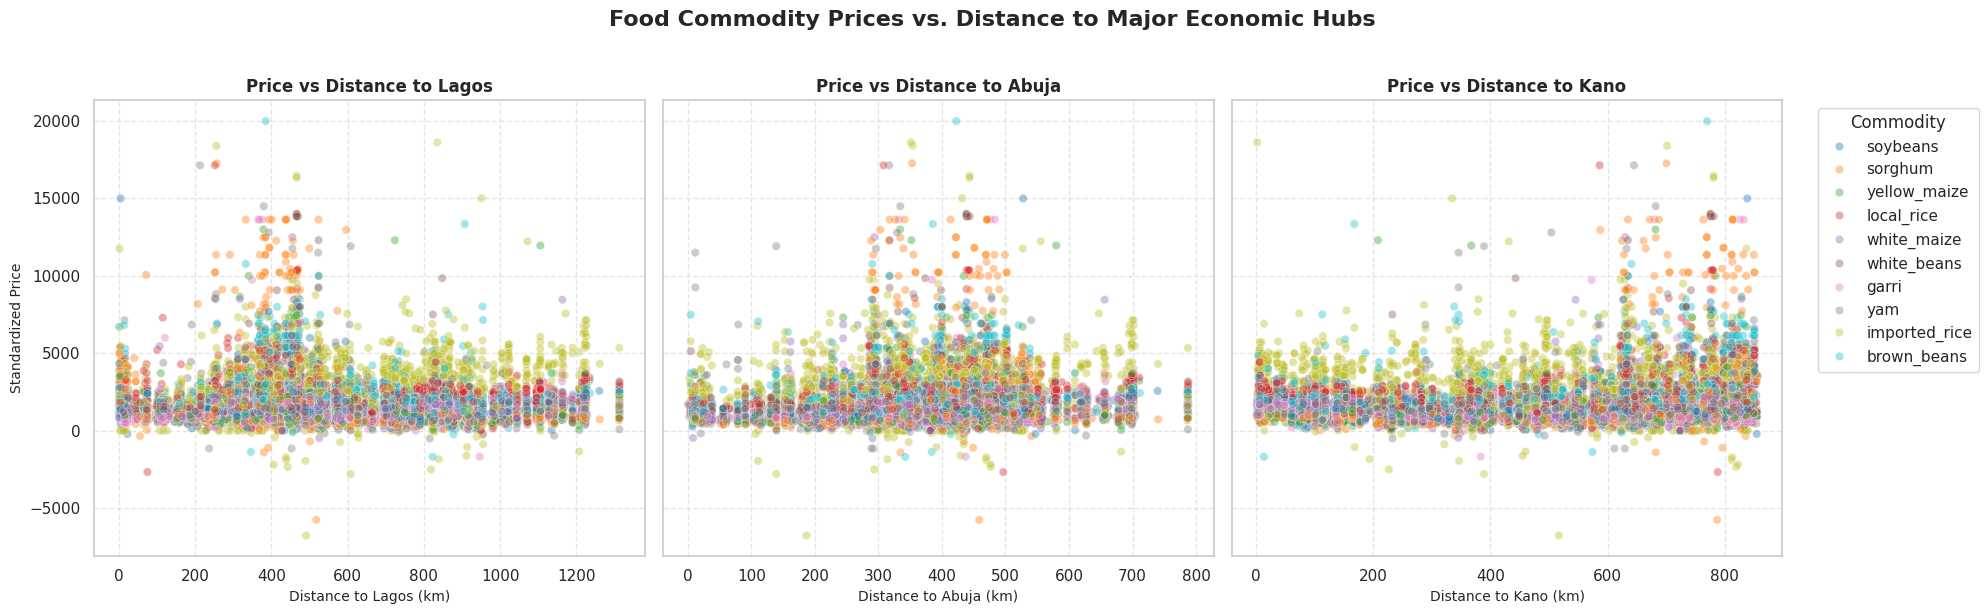

In [34]:

# Sample the data for faster plotting and clarity
plot_sample = df_melted.dropna(subset=['standardized_price']).sample(n=20000, random_state=42)

hubs_to_plot = ['lagos', 'abuja', 'kano']
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(20, 6), sharey=True)

for idx, hub in enumerate(hubs_to_plot):
    ax = axes[idx]
    sns.scatterplot(
        data=plot_sample,
        x=f'dist_to_{hub}_km',
        y='standardized_price',
        hue='commodity',
        alpha=0.4,
        palette='tab10',
        ax=ax,
        legend=(idx == 2) # Only show legend on the last plot to save space
    )
    ax.set_title(f"Price vs Distance to {hub.title()}", fontsize=12, fontweight='bold')
    ax.set_xlabel(f"Distance to {hub.title()} (km)", fontsize=10)
    if idx == 0:
        ax.set_ylabel("Standardized Price", fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.5)

if axes[2].get_legend() is not None:
    axes[2].legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Commodity')

plt.suptitle("Food Commodity Prices vs. Distance to Major Economic Hubs", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [35]:
df_melted.isna().sum()

,0
fid,0
date,0
zonelabel1,0
statelabel,0
lgalabel,0
sector,0
market_typ,0
price_cate,0
market_tim,0
gps_latitu,0


In [36]:
from google.colab import files

# 1. Rename df_melted to df_cleaned
df_cleaned = df_melted.copy()

# 2. Export to a CSV file
csv_path = 'df_cleaned.csv'
df_cleaned.to_csv(csv_path, index=False)
print(f"Successfully saved df_cleaned to local path: {csv_path}")

# 3. Trigger download to your local machine
files.download(csv_path)

Successfully saved df_cleaned to local path: df_cleaned.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil
import os

# Define your target Google Drive folder path
# Replace 'ML PROJECTS/MarketIQ' with whichever folder path you prefer inside your Drive
drive_folder = '/content/drive/MyDrive/ML PROJECTS/MarketIQ/data/cleaned'
os.makedirs(drive_folder, exist_ok=True)

target_path = os.path.join(drive_folder, 'df_cleaned.csv')

# Copy df_cleaned.csv directly to Google Drive
shutil.copy('df_cleaned.csv', target_path)
print(f"Successfully saved df_cleaned.csv directly to your Google Drive at: {target_path}")